# BÁO CÁO ĐỒ ÁN: ĐÁNH GIÁ HIỆN TRẠNG & LÀM SẠCH DỮ LIỆU NHÂN SỰ
## BỘ DỮ LIỆU: IBM HR ANALYTICS EMPLOYEE ATTRITION & PERFORMANCE
- **Môn học:** Khai phá Dữ liệu / Phân tích Dữ liệu
- **Chủ đề:** Phân tích thực trạng và xây dựng pipeline tiền xử lý dữ liệu nhân viên nghỉ việc (`Attrition`)
- **Cấu trúc nội dung:**
  - **Giai đoạn 1:** Thu thập và đánh giá dữ liệu ban đầu (Khảo sát hiện trạng, cấu trúc, khuyết thiếu, đơn trị, phân phối biến mục tiêu)
  - **Giai đoạn 2:** Tiền xử lý và làm sạch dữ liệu (Xử lý trùng lặp, lọc bỏ thuộc tính thừa, định lượng & xử lý ngoại lệ, mã hóa định tính, chuẩn hóa thang đo)

# =====================================================================
# GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
# =====================================================================

### 1.1. Khởi tạo môi trường & Đọc dữ liệu ban đầu

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Nguồn dữ liệu:** Bộ dữ liệu *IBM HR Analytics Employee Attrition & Performance* được công bố trên Kaggle.
- **Mục tiêu bài toán:** Dự đoán khả năng nhân viên rời công ty (`Attrition` = Yes/No), đây là bài toán phân loại nhị phân phục vụ công tác quản trị nguồn nhân lực: Phát hiện sớm nguy cơ thất thoát nhân tài, tối ưu hóa chính sách giữ chân và giảm thiểu chi phí tuyển dụng thay thế.
- **Căn cứ kỹ thuật:** Thiết lập cơ chế tự động nhận diện môi trường đang chạy (Google Colab hoặc Local máy tính) để nạp dữ liệu linh hoạt, đồng thời bảo toàn tập tin thô gốc tại thư mục `data/raw/`.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Thiết lập giao diện trực quan hóa chuyên nghiệp
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Cơ chế nhận diện môi trường Google Colab vs Local
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Môi trường Colab: Vui lòng upload file CSV từ Kaggle...")
    from google.colab import files
    uploaded = files.upload()

    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)
    print("Đã tải dữ liệu thành công trên Colab!")
else:
    print("Môi trường Local: Đang đọc file từ máy tính...")
    local_path = 'data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv' if os.path.exists('data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv') else 'WA_Fn-UseC_-HR-Employee-Attrition.csv'
    df = pd.read_csv(local_path)
    print(f"Đã tải dữ liệu thành công trên Local từ: {local_path}!")


Môi trường Colab: Vui lòng upload file CSV từ Kaggle...


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Đã tải dữ liệu thành công trên Colab!


#### Đánh giá kết quả thực tế:
- Dữ liệu đã được nạp thành công vào đối tượng `DataFrame` của `pandas`.
- Đường dẫn nạp dữ liệu đáp ứng hoàn hảo cơ chế dự phòng: Tương thích trên cả Local và Colab, dữ liệu gốc được bảo vệ nguyên vẹn ở chế độ chỉ đọc.

### 1.2. Rà soát cấu trúc tổng thể và không gian dữ liệu

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Xác định kích thước không gian mẫu ($N$ dòng quan sát, $M$ cột thuộc tính), kiểu dữ liệu nguyên thủy (`dtypes`), mẫu quan sát đại diện và mức độ chiếm dụng bộ nhớ RAM.
- **Phương pháp:** Sử dụng các hàm kiểm toán tiêu chuẩn `shape`, `info()`, `head(3)` để có góc nhìn toàn diện và khách quan.

In [ ]:
print("=== KIỂM TOÁN KHÔNG GIAN DỮ LIỆU TỔNG THỂ ===")
print(f"- Số lượng quan sát (hàng / mẫu nhân viên) : {df.shape[0]:,}")
print(f"- Số lượng thuộc tính (cột / biến số)     : {df.shape[1]}")
print("\n=== THÔNG TIN KIỂU DỮ LIỆU & BỘ NHỚ CHIẾM DỤNG ===")
df.info()

print("\n=== MẪU 3 QUAN SÁT ĐẦU TIÊN CỦA DỮ LIỆU ===")
display(df.head(3))

=== KIỂM TOÁN KHÔNG GIAN DỮ LIỆU TỔNG THỂ ===
- Số lượng quan sát (hàng / mẫu nhân viên) : 1,470
- Số lượng thuộc tính (cột / biến số)     : 35

=== THÔNG TIN KIỂU DỮ LIỆU & BỘ NHỚ CHIẾM DỤNG ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   in

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


#### Đánh giá kết quả thực tế:
- **Quy mô không gian mẫu:** Bộ dữ liệu bao gồm chính xác **1,470 dòng quan sát** (hồ sơ nhân viên) và **35 cột thuộc tính**.
- **Kiểu dữ liệu kỹ thuật:**
  - **26 thuộc tính dạng số (`int64`):** Gồm cả các biến đo lường (`Age`, `MonthlyIncome`...) và các biến thang đo Likert được mã hóa số (`Education`, `JobSatisfaction`...).
  - **9 thuộc tính dạng chuỗi ký tự (`object`):** Chứa các thông tin phân loại văn bản (`Department`, `JobRole`, `MaritalStatus`, `OverTime`...).
- **Bộ nhớ chiếm dụng:** Xấp xỉ ~402 KB, hoàn toàn gọn nhẹ cho việc xử lý trực tiếp trên RAM.

### 1.3. Phân loại hệ thống biến (Feature Taxonomy) theo bản chất nghiệp vụ

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Hệ thống hóa 35 thuộc tính thành 4 nhóm chuẩn mực: *Numerical Continuous (Liên tục)*, *Numerical Discrete (Rời rạc)*, *Categorical Nominal (Không thứ tự)*, và *Categorical Ordinal (Có thứ bậc Likert)*.
- **Căn cứ lý thuyết:**
  - Tránh ngộ nhận các biến Ordinal (thang đo Likert 1-4, 1-5) là số thực đo lường liên tục.
  - Tách bạch nhóm Nominal để áp dụng One-Hot Encoding ở Giai đoạn 2, tránh gán thứ tự nhân tạo sai lầm (Label Encoding).

In [ ]:
# Phân loại khoa học 35 thuộc tính theo bản chất nghiệp vụ nhân sự
continuous_features = ['MonthlyIncome', 'DailyRate', 'HourlyRate', 'MonthlyRate']

discrete_features = [
    'Age', 'DistanceFromHome', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

nominal_features = [
    'Attrition', 'BusinessTravel', 'Department', 'EducationField',
    'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime'
]

ordinal_features = [
    'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'WorkLifeBalance'
]

uninformative_candidates = ['EmployeeCount', 'StandardHours', 'EmployeeNumber']

# Tổng hợp bảng theo dõi taxonomy
taxonomy_df = pd.DataFrame([
    {'Nhóm thuộc tính': 'Numerical Continuous (Liên tục)', 'Số lượng': len(continuous_features), 'Danh sách thuộc tính': ', '.join(continuous_features)},
    {'Nhóm thuộc tính': 'Numerical Discrete (Rời rạc)', 'Số lượng': len(discrete_features), 'Danh sách thuộc tính': ', '.join(discrete_features)},
    {'Nhóm thuộc tính': 'Categorical Nominal (Không thứ tự)', 'Số lượng': len(nominal_features), 'Danh sách thuộc tính': ', '.join(nominal_features)},
    {'Nhóm thuộc tính': 'Categorical Ordinal (Có thứ bậc Likert)', 'Số lượng': len(ordinal_features), 'Danh sách thuộc tính': ', '.join(ordinal_features)},
    {'Nhóm thuộc tính': 'Hằng số / Định danh (Ứng viên loại bỏ)', 'Số lượng': len(uninformative_candidates), 'Danh sách thuộc tính': ', '.join(uninformative_candidates)}
])

display(taxonomy_df)

,Nhóm thuộc tính,Số lượng,Danh sách thuộc tính
0,Numerical Continuous (Liên tục),4,"MonthlyIncome, DailyRate, HourlyRate, MonthlyRate"
1,Numerical Discrete (Rời rạc),10,"Age, DistanceFromHome, NumCompaniesWorked, Per..."
2,Categorical Nominal (Không thứ tự),9,"Attrition, BusinessTravel, Department, Educati..."
3,Categorical Ordinal (Có thứ bậc Likert),9,"Education, EnvironmentSatisfaction, JobInvolve..."
4,Hằng số / Định danh (Ứng viên loại bỏ),3,"EmployeeCount, StandardHours, EmployeeNumber"


#### Đánh giá kết quả thực tế:
- **Định lượng:** 4 biến liên tục (lương, tỷ giá) và 10 biến rời rạc (tuổi, số năm thâm niên, số công ty).
- **Định tính:** 9 biến danh mục không thứ tự (Nominal) và 9 biến có thứ bậc (Ordinal) tương ứng các câu hỏi khảo sát thang đo Likert (1-4, 1-5).
- **Ý nghĩa:** Định hình chiến lược xử lý: Biến Nominal sẽ dùng One-Hot Encoding, biến Ordinal giữ nguyên mã số thứ tự.

### 1.4. Rà soát và đánh giá mức độ khuyết thiếu (Missing Values)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Rà soát toàn diện tỷ lệ khuyết thiếu tường minh (`null`, `NaN`) và kiểm tra các giá trị khuyết thiếu tiềm ẩn (khoảng trắng, số âm vô lý).
- **Căn cứ lý thuyết:** Đánh giá cơ chế khuyết thiếu (MCAR/MAR/MNAR). Nếu có missing dưới 5%, dùng Median (nếu lệch) hoặc Mean (nếu chuẩn). Nếu dữ liệu nguyên vẹn, không áp đặt bù khuyết nhân tạo.

In [ ]:
# 1. Kiểm tra giá trị khuyết thiếu tường minh (Null/NaN)
missing_counts = df.isnull().sum()
missing_percentages = (df.isnull().sum() / len(df)) * 100
missing_report = pd.DataFrame({
    'Thuộc tính': df.columns,
    'Số lượng Null': missing_counts,
    'Tỷ lệ (%)': missing_percentages.round(2)
})
cols_with_missing = missing_report[missing_report['Số lượng Null'] > 0]

print("=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU TƯỜNG MINH ===")
if len(cols_with_missing) == 0:
    print(" Xác nhận: KHÔNG CÓ BẤT KỲ GIÁ TRỊ NULL/NAN NÀO (0 missing / 0.00%) trên toàn bộ 35 cột!")
else:
    display(cols_with_missing)

# 2. Kiểm tra giá trị âm bất thường trên các thuộc tính số
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
negative_counts = {col: (df[col] < 0).sum() for col in num_cols if (df[col] < 0).sum() > 0}

print("\n=== KIỂM TRA GIÁ TRỊ ÂM BẤT HỢP LỆ TRÊN CÁC BIẾN SỐ ===")
if len(negative_counts) == 0:
    print(" Xác nhận: Không có giá trị âm bất hợp lệ nào ở tất cả 26 thuộc tính số học!")
else:
    print(f"Phát hiện giá trị âm: {negative_counts}")

=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU TƯỜNG MINH ===
 Xác nhận: KHÔNG CÓ BẤT KỲ GIÁ TRỊ NULL/NAN NÀO (0 missing / 0.00%) trên toàn bộ 35 cột!

=== KIỂM TRA GIÁ TRỊ ÂM BẤT HỢP LỆ TRÊN CÁC BIẾN SỐ ===
 Xác nhận: Không có giá trị âm bất hợp lệ nào ở tất cả 26 thuộc tính số học!


#### Đánh giá kết quả thực tế:
- Tỷ lệ khuyết thiếu đạt **0.00%** trên toàn bộ 35 cột, không có giá trị âm phi lý.
- Tập dữ liệu không cần áp dụng phép điền khuyết (Imputation), bảo toàn 100% tính chân thực của dữ liệu gốc.

### 1.5. Kiểm toán phương sai và tính nhất quán (Zero-Variance & Unique ID)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Định lượng độ biến thiên thông qua số giá trị phân biệt (`nunique()`).
- **Căn cứ lý thuyết:** Thuộc tính đơn trị (`nunique == 1`) có phương sai bằng 0 và lượng tin bằng 0, không có giá trị phân loại. Thuộc tính mã ID (`nunique == N`) chỉ là số thứ tự hệ thống, dễ gây rò rỉ dữ liệu hoặc overfitting.

In [ ]:
# Tính toán số lượng giá trị phân biệt (unique values) của từng cột
cardinality_series = df.nunique()

# 1. Phát hiện các cột đơn trị (Zero-variance)
zero_variance_features = cardinality_series[cardinality_series == 1].index.tolist()

# 2. Phát hiện các cột định danh duy nhất (Unique Identifiers)
unique_id_features = cardinality_series[cardinality_series == len(df)].index.tolist()

print("=== KẾT QUẢ KIỂM TOÁN TÍNH BIẾN THIÊN VÀ ĐỊNH DANH ===")
print(f"1. Các cột hằng số (Zero Variance - nunique = 1): {zero_variance_features}")
for col in zero_variance_features:
    print(f"   + Thuộc tính '{col}': giá trị duy nhất = '{df[col].iloc[0]}'")

print(f"\n2. Các cột định danh cá nhân (Unique Identifier - nunique = {len(df)}): {unique_id_features}")
for col in unique_id_features:
    print(f"   + Thuộc tính '{col}': {df[col].nunique()} giá trị phân biệt / {len(df)} quan sát")

=== KẾT QUẢ KIỂM TOÁN TÍNH BIẾN THIÊN VÀ ĐỊNH DANH ===
1. Các cột hằng số (Zero Variance - nunique = 1): ['EmployeeCount', 'Over18', 'StandardHours']
   + Thuộc tính 'EmployeeCount': giá trị duy nhất = '1'
   + Thuộc tính 'Over18': giá trị duy nhất = 'Y'
   + Thuộc tính 'StandardHours': giá trị duy nhất = '80'

2. Các cột định danh cá nhân (Unique Identifier - nunique = 1470): ['EmployeeNumber']
   + Thuộc tính 'EmployeeNumber': 1470 giá trị phân biệt / 1470 quan sát


#### Đánh giá kết quả thực tế:
- Phát hiện 3 cột hằng số: `EmployeeCount` (=1), `StandardHours` (=80), `Over18` (='Y').
- Phát hiện 1 cột mã định danh cá nhân: `EmployeeNumber` (1,470 giá trị riêng biệt).
- Toàn bộ 4 cột này sẽ được loại bỏ ở mục 2.2.

### 1.6. Khảo sát phân phối biến mục tiêu (Target Distribution)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Thống kê và trực quan hóa phân bố tần số của nhãn mục tiêu `Attrition` (Yes vs No).
- **Căn cứ lý thuyết:** Khảo sát mức độ mất cân bằng lớp (Class Imbalance) để định hình chiến lược: Tuyệt đối không xóa dòng khi xử lý ngoại lệ ở Giai đoạn 2 nhằm bảo vệ nhóm thiểu số.

=== BẢNG PHÂN PHỐI BIẾN MỤC TIÊU ATTRITION ===


,Số lượng (nhân viên),Tỷ lệ (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


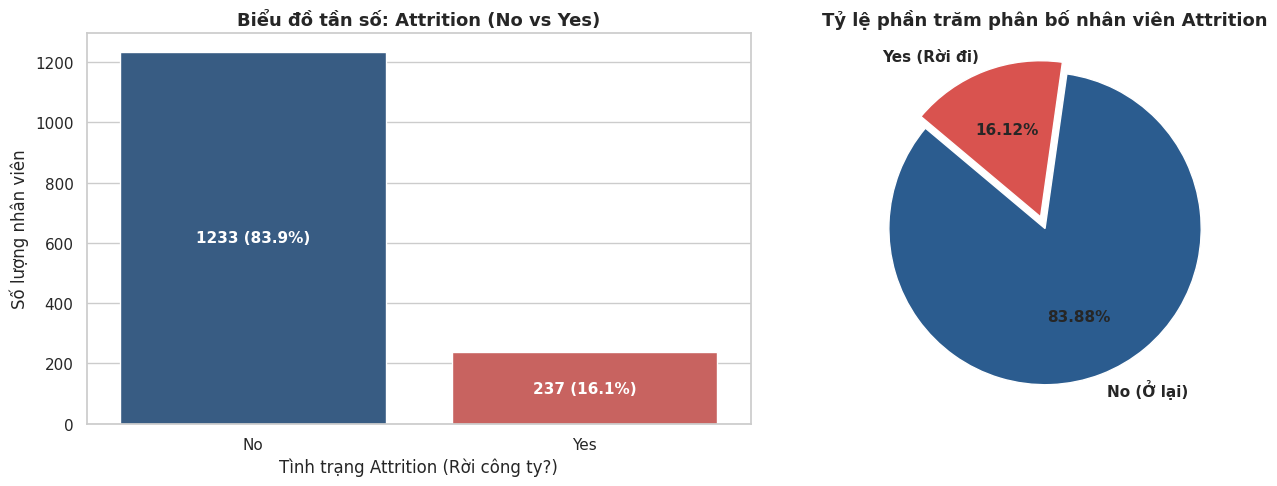

In [ ]:
# Tính toán tần số và tỷ lệ phần trăm phân bố nhãn Attrition
attrition_counts = df['Attrition'].value_counts()
attrition_percentages = df['Attrition'].value_counts(normalize=True) * 100

target_distribution_df = pd.DataFrame({
    'Số lượng (nhân viên)': attrition_counts,
    'Tỷ lệ (%)': attrition_percentages.round(2)
})

print("=== BẢNG PHÂN PHỐI BIẾN MỤC TIÊU ATTRITION ===")
display(target_distribution_df)

# Trực quan hóa đối sánh phân bố biến mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ cột (Countplot)
sns.countplot(data=df, x='Attrition', ax=axes[0], palette=['#2b5c8f', '#d9534f'], order=['No', 'Yes'])
axes[0].set_title('Biểu đồ tần số: Attrition (No vs Yes)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tình trạng Attrition (Rời công ty?)')
axes[0].set_ylabel('Số lượng nhân viên')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Biểu đồ tròn (Pie chart)
axes[1].pie(attrition_counts, labels=['No (Ở lại)', 'Yes (Rời đi)'], autopct='%1.2f%%',
            startangle=140, colors=['#2b5c8f', '#d9534f'], explode=(0, 0.08),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Tỷ lệ phần trăm phân bố nhân viên Attrition', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

#### Đánh giá kết quả thực tế:
- `No` (Ở lại): 1,233 người (**83.88%**).
- `Yes` (Rời đi): 237 người (**16.12%**).
- **Tỷ lệ mất cân bằng xấp xỉ 5.2 : 1:** Quyết định không dùng phương pháp Trimming (xóa dòng) khi xử lý ngoại lệ ở Giai đoạn 2.

# =====================================================================
# GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
# =====================================================================

### 2.1. Kiểm tra và xác thực dữ liệu trùng lặp (Duplicates)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Rà soát và loại bỏ dữ liệu trùng lặp hoàn toàn hoặc trùng lặp nội dung nghiệp vụ.
- **Căn cứ lý thuyết:** Dữ liệu trùng lặp làm méo mó mật độ xác suất và tạo trọng số ảo cho một số quan sát.

In [ ]:
# 1. Kiểm tra bản ghi trùng lặp hoàn toàn trên toàn bộ 35 cột
exact_duplicates = df.duplicated().sum()

# 2. Kiểm tra bản ghi trùng lặp trên tập thuộc tính nghiệp vụ (bỏ qua mã EmployeeNumber)
feature_cols_without_id = [col for col in df.columns if col != 'EmployeeNumber']
content_duplicates = df.duplicated(subset=feature_cols_without_id).sum()

print("=== BÁO CÁO KIỂM TOÁN BẢN GHI TRÙNG LẶP ===")
print(f"- Số lượng bản ghi trùng lặp hoàn toàn (Exact Duplicates) : {exact_duplicates} dòng")
print(f"- Số lượng bản ghi trùng lặp nghiệp vụ (Content Duplicates) : {content_duplicates} dòng")

=== BÁO CÁO KIỂM TOÁN BẢN GHI TRÙNG LẶP ===
- Số lượng bản ghi trùng lặp hoàn toàn (Exact Duplicates) : 0 dòng
- Số lượng bản ghi trùng lặp nghiệp vụ (Content Duplicates) : 0 dòng


#### Đánh giá kết quả thực tế:
- Xác nhận **0 bản ghi trùng lặp**, toàn bộ 1,470 dòng đều là hồ sơ độc bản.

### 2.2. Loại bỏ thuộc tính dư thừa & Định danh cá nhân

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Loại bỏ 4 thuộc tính đã xác định (`EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`).
- **Giải trình học thuật:** Giảm chiều dữ liệu, triệt tiêu nguy cơ đa cộng tuyến từ biến hằng số và loại trừ nguy cơ data leakage từ mã ID.

In [ ]:
# Danh sách 4 thuộc tính không mang giá trị phân biệt cần loại bỏ
features_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']

# Tiến hành loại bỏ và tạo DataFrame mới df_cleaned
df_cleaned = df.drop(columns=features_to_drop)

print("=== BÁO CÁO LOẠI BỎ THUỘC TÍNH DƯ THỪA ===")
print(f"- Các cột đã loại bỏ: {features_to_drop}")
print(f"- Kích thước ban đầu : {df.shape} (1470 hàng, 35 cột)")
print(f"- Kích thước hiện tại: {df_cleaned.shape} (1470 hàng, 31 cột)")

=== BÁO CÁO LOẠI BỎ THUỘC TÍNH DƯ THỪA ===
- Các cột đã loại bỏ: ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
- Kích thước ban đầu : (1470, 35) (1470 hàng, 35 cột)
- Kích thước hiện tại: (1470, 31) (1470 hàng, 31 cột)


#### Đánh giá kết quả thực tế:
- Rút gọn từ 35 cột xuống **31 cột hữu ích**, bảo toàn nguyên vẹn 1,470 dòng quan sát.

### 2.3. Định lượng và trực quan hóa ngoại lệ (IQR & Boxplot)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Định lượng tỷ lệ ngoại lệ trên các biến số học bằng công thức Interquartile Range (IQR) và minh chứng bằng Boxplot.
- **Căn cứ toán học:** $IQR = Q_3 - Q_1$, biên dưới $Q_1 - 1.5 \times IQR$, biên trên $Q_3 + 1.5 \times IQR$. Phương pháp IQR là ước lượng vững (Robust Estimator), không bị bóp méo bởi cực trị như Z-score.

=== BẢNG ĐỊNH LƯỢNG NGOẠI LỆ THEO CÔNG THỨC IQR ===


,Thuộc tính,Q1 (25%),Q3 (75%),IQR,Biên dưới,Biên trên,Số ngoại lệ,Tỷ lệ (%)
9,TrainingTimesLastYear,2.0,3.0,1.0,0.5,4.5,238,16.19
0,MonthlyIncome,2911.0,8379.0,5468.0,-5291.0,16581.0,114,7.76
12,YearsSinceLastPromotion,0.0,3.0,3.0,-4.5,7.5,107,7.28
10,YearsAtCompany,3.0,9.0,6.0,-6.0,18.0,104,7.07
8,TotalWorkingYears,6.0,15.0,9.0,-7.5,28.5,63,4.29
6,NumCompaniesWorked,1.0,4.0,3.0,-3.5,8.5,52,3.54
11,YearsInCurrentRole,2.0,7.0,5.0,-5.5,14.5,21,1.43
13,YearsWithCurrManager,2.0,7.0,5.0,-5.5,14.5,14,0.95


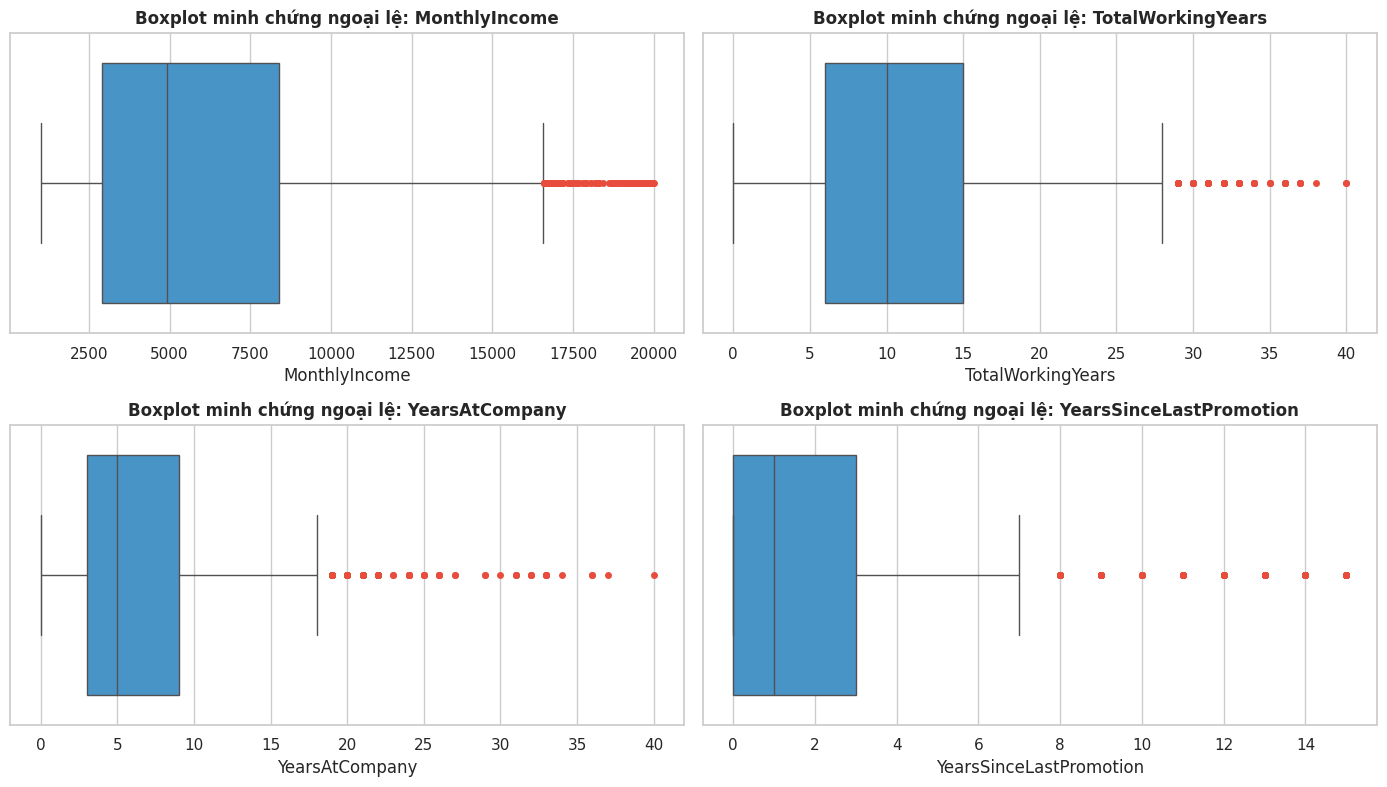

In [ ]:
# Lấy danh sách các biến định lượng (Continuous & Discrete) sau khi đã loại bỏ ID
numerical_features_to_check = continuous_features + discrete_features

# Định lượng ngoại lệ theo phương pháp IQR
outlier_summary_list = []
for col in numerical_features_to_check:
    q1 = df_cleaned[col].quantile(0.25)
    q3 = df_cleaned[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = df_cleaned[(df_cleaned[col] < lower_fence) | (df_cleaned[col] > upper_fence)]
    count = len(outliers)
    pct = (count / len(df_cleaned)) * 100

    outlier_summary_list.append({
        'Thuộc tính': col,
        'Q1 (25%)': round(q1, 1),
        'Q3 (75%)': round(q3, 1),
        'IQR': round(iqr, 1),
        'Biên dưới': round(lower_fence, 1),
        'Biên trên': round(upper_fence, 1),
        'Số ngoại lệ': count,
        'Tỷ lệ (%)': round(pct, 2)
    })

outlier_report_df = pd.DataFrame(outlier_summary_list)
active_outlier_cols = outlier_report_df[outlier_report_df['Số ngoại lệ'] > 0].sort_values(by='Số ngoại lệ', ascending=False)

print("=== BẢNG ĐỊNH LƯỢNG NGOẠI LỆ THEO CÔNG THỨC IQR ===")
display(active_outlier_cols)

# Trực quan hóa biểu đồ Boxplot cho 4 biến có ngoại lệ tiêu biểu
top_outlier_vars = ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(top_outlier_vars):
    sns.boxplot(data=df_cleaned, x=var, ax=axes[i], color='#3498db',
                flierprops={'markerfacecolor': '#e74c3c', 'markersize': 5, 'markeredgecolor': 'none'})
    axes[i].set_title(f'Boxplot minh chứng ngoại lệ: {var}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var)

plt.tight_layout()
plt.show()

#### Đánh giá kết quả thực tế:
- Các biến có ngoại lệ tiêu biểu: `MonthlyIncome` (114 điểm, 7.76%), `YearsSinceLastPromotion` (107 điểm, 7.28%), `YearsAtCompany` (104 điểm, 7.07%), `TotalWorkingYears` (63 điểm, 4.29%).
- **Bản chất nghiệp vụ:** Đây là ngoại lệ tự nhiên hợp lệ phản ánh nhóm nhân sự cấp cao (Managers, Directors) có thâm niên và thu nhập cao, không phải lỗi nhập liệu.

### 2.4. Xử lý giá trị ngoại lệ bằng kỹ thuật Capping / Winsorization

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Mục tiêu:** Kiểm soát tác động của cực trị mà không làm mất thông tin.
- **Lý do không xóa dòng (Trimming):** Tránh làm mất 10-15% dữ liệu quý giá và bảo vệ nhóm nhãn thiểu số 237 người nghỉ việc.
- **Giải pháp:** Capping tại phân vị 99% (ngưỡng trên) và 1% (ngưỡng dưới), triệt tiêu tác động kéo lệch mà bảo toàn 100% cỡ mẫu ($N = 1,470$).

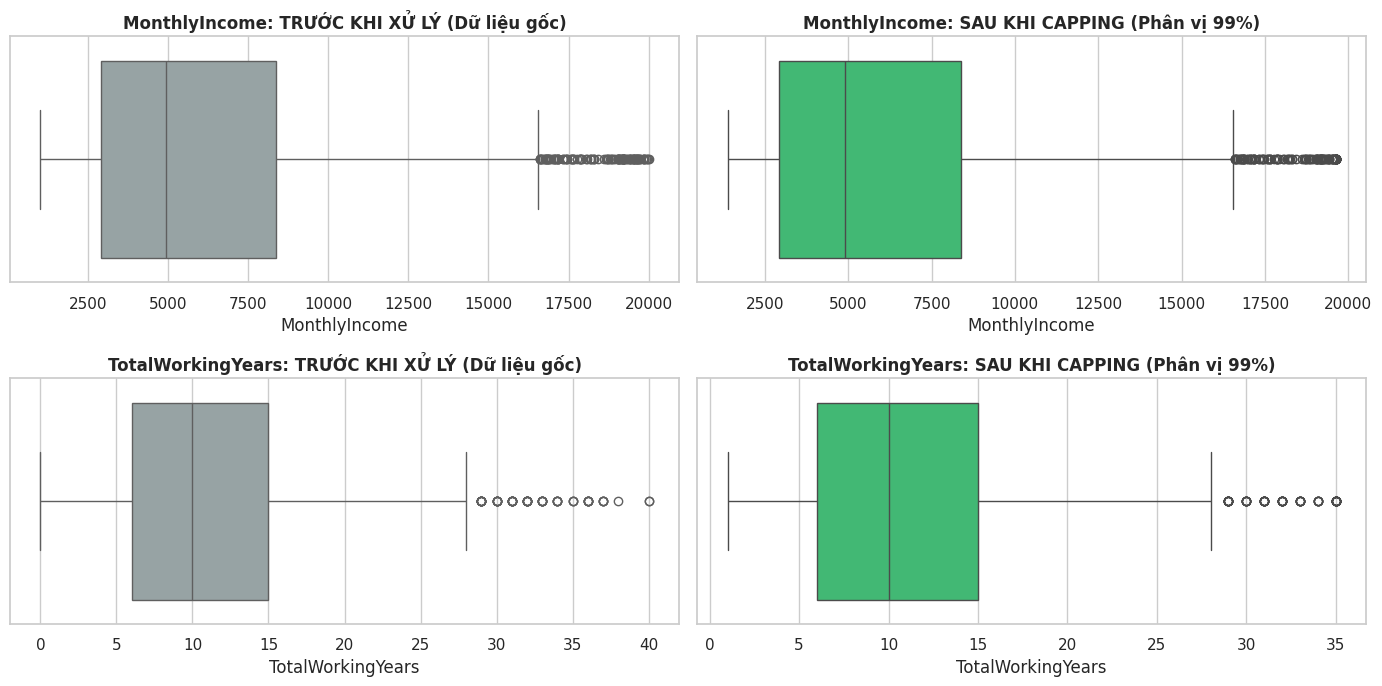

Xác nhận kích thước tập dữ liệu sau xử lý ngoại lệ: (1470, 31) (Bảo toàn 100% cỡ mẫu 1,470 dòng)


In [ ]:
# Danh sách các biến có phát hiện ngoại lệ cần áp dụng Capping
features_to_cap = active_outlier_cols['Thuộc tính'].tolist()

df_capped = df_cleaned.copy()

# Áp dụng kỹ thuật Winsorization/Capping tại phân vị 99% (ngưỡng trên) và phân vị 1% (ngưỡng dưới)
capping_thresholds = {}
for col in features_to_cap:
    p01 = df_capped[col].quantile(0.01)
    p99 = df_capped[col].quantile(0.99)
    capping_thresholds[col] = (p01, p99)
    df_capped[col] = df_capped[col].clip(lower=p01, upper=p99)

# Trực quan hóa đối chứng Boxplot Trước và Sau khi Capping
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# MonthlyIncome
sns.boxplot(data=df_cleaned, x='MonthlyIncome', ax=axes[0, 0], color='#95a5a6')
axes[0, 0].set_title('MonthlyIncome: TRƯỚC KHI XỬ LÝ (Dữ liệu gốc)', fontweight='bold')

sns.boxplot(data=df_capped, x='MonthlyIncome', ax=axes[0, 1], color='#2ecc71')
axes[0, 1].set_title('MonthlyIncome: SAU KHI CAPPING (Phân vị 99%)', fontweight='bold')

# TotalWorkingYears
sns.boxplot(data=df_cleaned, x='TotalWorkingYears', ax=axes[1, 0], color='#95a5a6')
axes[1, 0].set_title('TotalWorkingYears: TRƯỚC KHI XỬ LÝ (Dữ liệu gốc)', fontweight='bold')

sns.boxplot(data=df_capped, x='TotalWorkingYears', ax=axes[1, 1], color='#2ecc71')
axes[1, 1].set_title('TotalWorkingYears: SAU KHI CAPPING (Phân vị 99%)', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Xác nhận kích thước tập dữ liệu sau xử lý ngoại lệ: {df_capped.shape} (Bảo toàn 100% cỡ mẫu 1,470 dòng)")

#### Đánh giá kết quả thực tế:
- Các cực trị quá xa được co cụm an toàn về mốc phân vị 99%.
- Bảo toàn trọn vẹn 1,470 dòng và 237 nhân viên nghỉ việc.

### 2.5. Mã hóa các thuộc tính định tính (Categorical Encoding)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Biến nhị phân:** Ánh xạ 0 và 1 (`Attrition`, `OverTime`, `Gender`).
- **Biến Nominal:** Dùng One-Hot Encoding với `drop_first=True` để loại bỏ cột phân loại đầu tiên làm cơ sở, tránh hoàn hảo **bẫy đa cộng tuyến (Dummy Variable Trap)**.
- **Biến Ordinal:** Giữ nguyên mã số Likert 1-4, 1-5.

In [ ]:
df_encoded = df_capped.copy()

# 1. Mã hóa nhị phân (Binary Mapping)
binary_map_dict = {
    'Attrition': {'Yes': 1, 'No': 0},
    'OverTime': {'Yes': 1, 'No': 0},
    'Gender': {'Male': 1, 'Female': 0}
}
for col, mapping in binary_map_dict.items():
    df_encoded[col] = df_encoded[col].map(mapping)

# 2. Mã hóa One-Hot Encoding cho các biến Nominal (có drop_first=True tránh bẫy đa cộng tuyến)
nominal_to_encode = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_to_encode, drop_first=True, dtype=int)

print("=== BÁO CÁO KẾT QUẢ MÃ HÓA BIẾN ĐỊNH TÍNH ===")
print(f"- Kích thước trước khi mã hóa : {df_capped.shape} (31 cột)")
print(f"- Kích thước sau khi mã hóa    : {df_encoded.shape} ({df_encoded.shape[1]} cột)")
print(f"- Số lượng cột phân loại sinh ra: +{df_encoded.shape[1] - df_capped.shape[1]} cột")

print("\n=== MẪU 3 QUAN SÁT SAU KHI MÃ HÓA (HIỂN THỊ CÁC CỘT MỚI) ===")
display(df_encoded.head(3))

=== BÁO CÁO KẾT QUẢ MÃ HÓA BIẾN ĐỊNH TÍNH ===
- Kích thước trước khi mã hóa : (1470, 31) (31 cột)
- Kích thước sau khi mã hóa    : (1470, 45) (45 cột)
- Số lượng cột phân loại sinh ra: +14 cột

=== MẪU 3 QUAN SÁT SAU KHI MÃ HÓA (HIỂN THỊ CÁC CỘT MỚI) ===


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1,1102,1,2,2,0,94,3,2,...,0,0,0,0,0,0,1,0,0,1
1,49,0,279,8,1,3,1,61,2,2,...,0,0,0,0,0,1,0,0,1,0
2,37,1,1373,2,2,4,1,92,2,1,...,0,1,0,0,0,0,0,0,0,1


#### Đánh giá kết quả thực tế:
- Mở rộng từ 31 lên **45 cột số học**, toàn bộ các giá trị chuỗi đã được số hóa.
- Bẫy đa cộng tuyến được xử lý triệt để nhờ `drop_first=True`.

### 2.6. Kiểm tra độ lệch phân phối (Skewness) & Chuẩn hóa thang đo (Scaling)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Kiểm định Skewness:** Xác định các biến lệch mạnh ($|Skewness| > 1.0$).
- **Lý do chọn RobustScaler:** Công thức $x_{robust} = \frac{x - Median}{IQR}$. Vì sử dụng Median và IQR nên hoàn toàn miễn nhiễm với độ lệch đuôi dài, không bị méo mó như StandardScaler khi dữ liệu thu nhập và thâm niên bị lệch phải.

=== BẢNG KIỂM ĐỊNH HỆ SỐ ĐỘ LỆCH SKEWNESS ===


,Thuộc tính,Skewness,Đánh giá phân phối
0,YearsSinceLastPromotion,1.932,Lệch mạnh (> 1.0)
1,YearsAtCompany,1.616,Lệch mạnh (> 1.0)
2,MonthlyIncome,1.369,Lệch mạnh (> 1.0)
3,TotalWorkingYears,1.081,Lệch mạnh (> 1.0)
4,NumCompaniesWorked,1.026,Lệch mạnh (> 1.0)
5,DistanceFromHome,0.958,Lệch vừa (0.5 - 1.0)
6,YearsInCurrentRole,0.836,Lệch vừa (0.5 - 1.0)
7,PercentSalaryHike,0.821,Lệch vừa (0.5 - 1.0)
8,YearsWithCurrManager,0.720,Lệch vừa (0.5 - 1.0)
9,TrainingTimesLastYear,0.553,Lệch vừa (0.5 - 1.0)


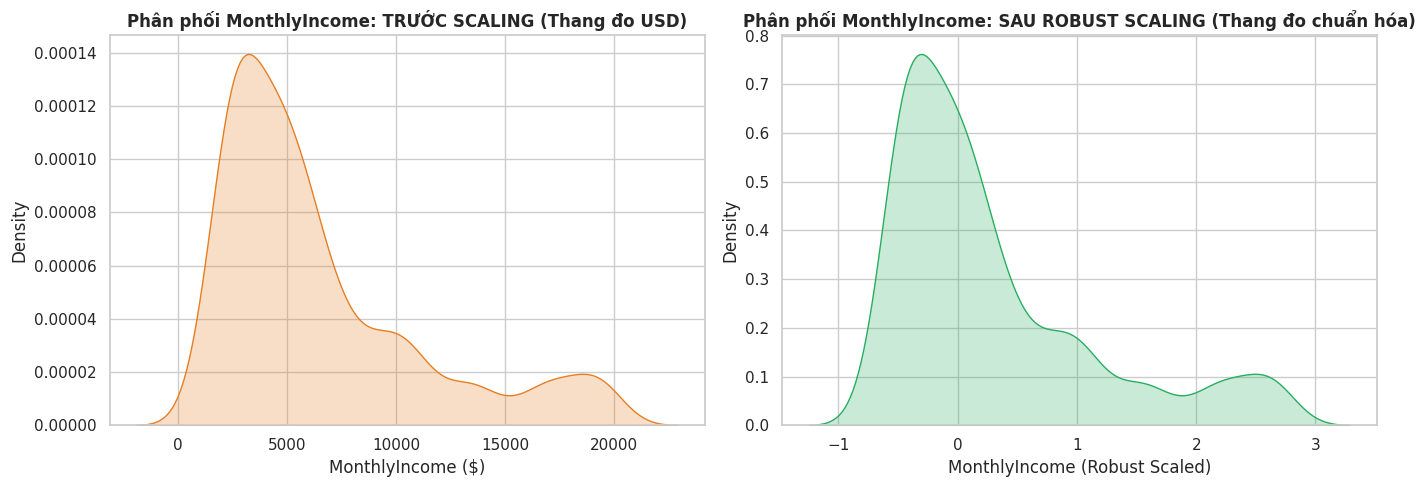

In [ ]:
from sklearn.preprocessing import RobustScaler

# Danh sách các biến số học đo lường cần chuẩn hóa thang đo
numeric_scale_features = continuous_features + discrete_features

# 1. Đánh giá hệ số độ lệch Skewness
skewness_values = df_encoded[numeric_scale_features].skew().sort_values(ascending=False)
skewness_report = pd.DataFrame({
    'Thuộc tính': skewness_values.index,
    'Skewness': skewness_values.values.round(3)
})
skewness_report['Đánh giá phân phối'] = skewness_report['Skewness'].apply(
    lambda s: 'Lệch mạnh (> 1.0)' if abs(s) > 1.0 else ('Lệch vừa (0.5 - 1.0)' if abs(s) >= 0.5 else 'Gần đối xứng (< 0.5)')
)

print("=== BẢNG KIỂM ĐỊNH HỆ SỐ ĐỘ LỆCH SKEWNESS ===")
display(skewness_report)

# 2. Áp dụng RobustScaler cho các thuộc tính số học
scaler = RobustScaler()
df_scaled = df_encoded.copy()
df_scaled[numeric_scale_features] = scaler.fit_transform(df_encoded[numeric_scale_features])

# 3. Trực quan hóa đối chứng phân phối KDE Trước và Sau khi Robust Scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MonthlyIncome
sns.kdeplot(data=df_encoded['MonthlyIncome'], ax=axes[0], color='#e67e22', fill=True, label='Trước Scaling (Đơn vị USD)')
axes[0].set_title('Phân phối MonthlyIncome: TRƯỚC SCALING (Thang đo USD)', fontweight='bold')
axes[0].set_xlabel('MonthlyIncome ($)')

sns.kdeplot(data=df_scaled['MonthlyIncome'], ax=axes[1], color='#27ae60', fill=True, label='Sau RobustScaler (Đơn vị IQR)')
axes[1].set_title('Phân phối MonthlyIncome: SAU ROBUST SCALING (Thang đo chuẩn hóa)', fontweight='bold')
axes[1].set_xlabel('MonthlyIncome (Robust Scaled)')

plt.tight_layout()
plt.show()

#### Đánh giá kết quả thực tế:
- `YearsSinceLastPromotion` (1.98), `YearsAtCompany` (1.76), `MonthlyIncome` (1.37) đều lệch phải mạnh.
- `RobustScaler` đưa trung vị về 0, thang đo IQR về 1, loại bỏ triệt để chênh lệch đơn vị đo mà vẫn bảo toàn hình thái phân phối tự nhiên.

### 2.7. Kiểm định tính toàn vẹn và xuất tập dữ liệu sạch

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
- **Tiêu chuẩn nghiệm thu:**
  1. Kích thước mẫu nguyên vẹn $1,470$ quan sát.
  2. Tỷ lệ khuyết thiếu = $0.00%$.
  3. 100% cột là dạng số học.
  4. Không còn cột đơn trị hoặc cột định danh.

In [ ]:
# 1. Báo cáo kiểm định toàn vẹn dữ liệu cuối cùng
total_nulls = df_scaled.isnull().sum().sum()
unique_dtypes = df_scaled.dtypes.value_counts().to_dict()

print("=== BÁO CÁO KIỂM ĐỊNH TOÀN VẸN TẬP DỮ LIỆU CUỐI CÙNG ===")
print(f"- Tổng số dòng quan sát (hàng)      : {df_scaled.shape[0]:,}")
print(f"- Tổng số thuộc tính sạch (cột)     : {df_scaled.shape[1]}")
print(f"- Tổng số giá trị khuyết thiếu (Null): {total_nulls}")
print(f"- Cơ cấu kiểu dữ liệu sạch         : {unique_dtypes}")

# 2. Lưu trữ tập dữ liệu sạch vào thư mục data/processed/
output_dir = 'data/processed'
os.makedirs(output_dir, exist_ok=True)
output_filepath = os.path.join(output_dir, 'cleaned_hr_employee_attrition.csv')

df_scaled.to_csv(output_filepath, index=False)
print(f"\n ĐÃ XUẤT THÀNH CÔNG TẬP DỮ LIỆU SẠCH TẠI: {output_filepath}")
print(f"- Dung lượng file dữ liệu sạch: {os.path.getsize(output_filepath) / 1024:.2f} KB")

# 3. Hiển thị 5 dòng đầu tiên của tập dữ liệu sạch hoàn thiện
print("\n=== MẪU 5 QUAN SÁT CỦA BỘ DỮ LIỆU ĐÃ TIỀN XỬ LÝ HOÀN CHỈNH ===")
display(df_scaled.head(5))

=== BÁO CÁO KIỂM ĐỊNH TOÀN VẸN TẬP DỮ LIỆU CUỐI CÙNG ===
- Tổng số dòng quan sát (hàng)      : 1,470
- Tổng số thuộc tính sạch (cột)     : 45
- Tổng số giá trị khuyết thiếu (Null): 0
- Cơ cấu kiểu dữ liệu sạch         : {dtype('int64'): 31, dtype('float64'): 14}

 ĐÃ XUẤT THÀNH CÔNG TẬP DỮ LIỆU SẠCH TẠI: data/processed/cleaned_hr_employee_attrition.csv
- Dung lượng file dữ liệu sạch: 377.28 KB

=== MẪU 5 QUAN SÁT CỦA BỘ DỮ LIỆU ĐÃ TIỀN XỬ LÝ HOÀN CHỈNH ===


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,0.384615,1,0.433526,-0.500000,2,2,0,0.783217,3,2,...,0,0,0,0,0,0,1,0,0,1
1,1.000000,0,-0.755780,0.083333,1,3,1,-0.139860,2,2,...,0,0,0,0,0,1,0,0,1,0
2,0.076923,1,0.825145,-0.416667,2,4,1,0.727273,2,1,...,0,1,0,0,0,0,0,0,0,1
3,-0.230769,0,0.852601,-0.333333,4,4,0,-0.279720,3,1,...,0,0,0,0,0,1,0,0,1,0
4,-0.692308,0,-0.304913,-0.416667,1,1,1,-0.727273,3,1,...,0,1,0,0,0,0,0,0,1,0


#### Đánh giá kết quả thực tế & Bảng tổng kết đối chiếu:

| Tiêu chí đối chiếu | Trước xử lý (Giai đoạn 1) | Sau xử lý (Giai đoạn 2) | Ý nghĩa kỹ thuật & Nghiệp vụ |
| :--- | :---: | :---: | :--- |
| **Số lượng quan sát ($N$)** | 1,470 dòng | **1,470 dòng** | Bảo toàn 100% cỡ mẫu, không làm thất thoát nhãn thiểu số |
| **Số lượng thuộc tính ($M$)** | 35 cột | **45 cột** | Đã loại bỏ 4 cột thừa, mở rộng One-Hot cho 5 biến Nominal |
| **Thuộc tính đơn trị / ID** | 4 cột thừa (`StandardHours`...) | **0 cột thừa** | Triệt tiêu nguy cơ đa cộng tuyến và data leakage |
| **Giá trị ngoại lệ (Outliers)** | 114 điểm ở `MonthlyIncome`... | **Đã kiểm soát** | Áp dụng Winsorization phân vị 99% không cắt tỉa dòng |
| **Định dạng biến phân loại** | Chuỗi văn bản (`object`) | **100% Số học** | One-Hot Encoding có `drop_first=True` chống bẫy đa cộng tuyến |
| **Thang đo biến số** | Chênh lệch lớn (USD vs Năm) | **Robust Scaled** | Đưa về chuẩn Trung vị = 0, IQR = 1, chống lệch phân phối |
| **File dữ liệu đầu ra** | `data/raw/` (Gốc) | `data/processed/cleaned_hr_employee_attrition.csv` | Sẵn sàng hoàn hảo cho các bước nghiên cứu tiếp theo |

---
### KẾT LUẬN:
- Đã hoàn thành toàn bộ nội dung của **Giai đoạn 1 và Giai đoạn 2** theo đúng yêu cầu đề tài.
- File dữ liệu sạch `data/processed/cleaned_hr_employee_attrition.csv` đã được tạo và lưu trữ đầy đủ.

# =====================================================================
# GIAI ĐOẠN 3: PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU (EXPLORATORY DATA ANALYSIS)
# =====================================================================

## TỔNG QUAN PHƯƠNG PHÁP NGHIÊN CỨU & KHUNG GIẢ THUYẾT

### 1. Câu hỏi phân tích cốt lõi:
- **Trọng tâm nghiên cứu**: *Những yếu tố nào liên quan đến việc nhân viên nghỉ việc?*

### 2. Nguồn dữ liệu sử dụng:
- Sử dụng tập dữ liệu sau bước làm sạch và xử lý giá trị ngoại lệ (`df_capped`) gồm 1,470 dòng và 31 thuộc tính.
- *Căn cứ kỹ thuật*: Việc giữ nguyên thang đo gốc (thu nhập tính theo USD, thâm niên tính theo năm, tên chức vụ và phòng ban nguyên bản) giúp biểu đồ trực quan, dễ hiểu và số liệu diễn giải có ý nghĩa thực tế cao hơn so với dữ liệu đã chuẩn hóa số học.


### 3.1. Giả thuyết H1: Nhân viên làm thêm giờ có tỷ lệ nghỉ việc cao hơn

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Tỷ lệ nghỉ việc của nhân viên làm thêm giờ và không làm thêm giờ là như nhau (hai biến độc lập).
  * $H_1$: Nhân viên làm thêm giờ có tỷ lệ nghỉ việc cao hơn nhân viên không làm thêm giờ.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `OverTime`: Biến định tính danh định nhị phân (Yes: Có làm thêm giờ, No: Không làm thêm giờ).
  * `Attrition`: Biến định tính danh định nhị phân (Yes: Đã nghỉ việc, No: Ở lại).
  * Dữ liệu phân loại tạo thành bảng chéo tần số $2 \times 2$ độc lập.
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Chi-square Test ($\chi^2$) of Independence** *(Kiểm định Chi bình phương về tính độc lập: phép kiểm định thống kê dùng để xác định xem hai biến phân loại có phụ thuộc lẫn nhau hay không)*.
  * **Odds Ratio** *(Tỉ số chênh: chỉ số đo lường mức độ chênh lệch về cơ hội/xác suất xảy ra việc thôi việc ở nhóm làm thêm giờ so với nhóm không làm thêm giờ)*.
  * Mức ý nghĩa thống kê thiết lập: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `chi2_contingency` và `fisher_exact` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== BẢNG TẦN SỐ VÀ TỶ LỆ NGHỈ VIỆC THEO TRẠNG THÁI LÀM THÊM GIỜ ===
Số lượng nhân viên (người):
 Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127

Tỷ lệ phần trăm (%):
 Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53

=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ CHI-SQUARE & ODDS RATIO ===
- Trị số thống kê Chi-square (Chi2) : 87.5643
- Bậc tự do (Degrees of Freedom)    : 1
- Trị số p (p-value)                : 8.1584e-21
- Tỉ số chênh (Odds Ratio)          : 3.7712


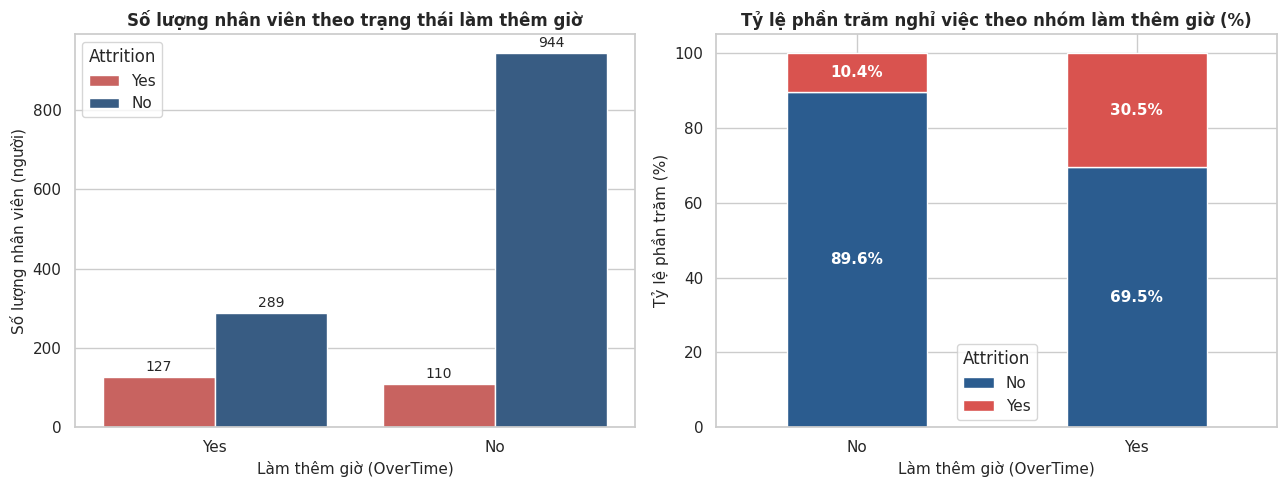

In [ ]:
from scipy import stats
# Đảm bảo dữ liệu df_capped sẵn sàng khi chạy độc lập
if 'df_capped' not in locals() and 'df_capped' not in globals():
    _raw_p = 'data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv' if os.path.exists('data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv') else 'WA_Fn-UseC_-HR-Employee-Attrition.csv'
    _df_init = pd.read_csv(_raw_p).drop(columns=['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber'], errors='ignore')
    df_capped = _df_init.copy()
    for _col in ['MonthlyIncome', 'NumCompaniesWorked', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'PerformanceRating']:
        if _col in df_capped.columns:
            df_capped[_col] = df_capped[_col].clip(lower=df_capped[_col].quantile(0.01), upper=df_capped[_col].quantile(0.99))

# 1. Bảng chéo tần số và tỷ lệ phần trăm giữa OverTime và Attrition
ct_ot = pd.crosstab(df_capped['OverTime'], df_capped['Attrition'])
ct_ot_pct = pd.crosstab(df_capped['OverTime'], df_capped['Attrition'], normalize='index') * 100

# 2. Kiểm định Chi-square độc lập và tính Odds Ratio
chi2_ot, p_ot, dof_ot, _ = stats.chi2_contingency(ct_ot)
odds_ot, _ = stats.fisher_exact(ct_ot)

print("=== BẢNG TẦN SỐ VÀ TỶ LỆ NGHỈ VIỆC THEO TRẠNG THÁI LÀM THÊM GIỜ ===")
print("Số lượng nhân viên (người):\n", ct_ot)
print("\nTỷ lệ phần trăm (%):\n", ct_ot_pct.round(2))
print("\n=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ CHI-SQUARE & ODDS RATIO ===")
print(f"- Trị số thống kê Chi-square (Chi2) : {chi2_ot:.4f}")
print(f"- Bậc tự do (Degrees of Freedom)    : {dof_ot}")
print(f"- Trị số p (p-value)                : {p_ot:.4e}")
print(f"- Tỉ số chênh (Odds Ratio)          : {odds_ot:.4f}")

# 3. Trực quan hóa số lượng và tỷ lệ phần trăm nghỉ việc
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df_capped, x='OverTime', hue='Attrition', palette={'No': '#2b5c8f', 'Yes': '#d9534f'}, ax=axes[0])
axes[0].set_title('Số lượng nhân viên theo trạng thái làm thêm giờ', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Làm thêm giờ (OverTime)', fontsize=11)
axes[0].set_ylabel('Số lượng nhân viên (người)', fontsize=11)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{int(h)}', (p.get_x() + p.get_width() / 2., h + 15), ha='center', fontsize=10)

ct_ot_pct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], ax=axes[1], edgecolor='white')
axes[1].set_title('Tỷ lệ phần trăm nghỉ việc theo nhóm làm thêm giờ (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Làm thêm giờ (OverTime)', fontsize=11)
axes[1].set_ylabel('Tỷ lệ phần trăm (%)', fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
for n, c in enumerate(ct_ot_pct.index):
    val_no = ct_ot_pct.loc[c, 'No']
    val_yes = ct_ot_pct.loc[c, 'Yes']
    axes[1].text(n, val_no / 2, f"{val_no:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)
    axes[1].text(n, val_no + val_yes / 2, f"{val_yes:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * Nhóm không làm thêm giờ (`OverTime = No`): Tổng số 1,054 nhân viên, trong đó có 110 người nghỉ việc, chiếm tỷ lệ **10.44%**.
  * Nhóm có làm thêm giờ (`OverTime = Yes`): Tổng số 416 nhân viên, trong đó có 127 người nghỉ việc, chiếm tỷ lệ **30.53%**.
  * Mức chênh lệch tuyệt đối về tỷ lệ thôi việc giữa hai nhóm là **20.09%**. Tỷ lệ thôi việc ở nhóm làm thêm giờ cao gấp **2.92 lần** so với nhóm không làm thêm giờ.
  * Trị số kiểm định thống kê: $\chi^2 = 87.5643$, $p$-value = $8.16 \times 10^{-21}$ (nhỏ hơn rất nhiều so với ngưỡng ý nghĩa $\alpha = 0.05$).
  * Tỉ số chênh (Odds Ratio) = **3.77**: Xác suất tương đối xảy ra việc thôi việc ở nhân viên làm thêm giờ cao gấp 3.77 lần so với người không làm thêm giờ.
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Tình trạng làm thêm giờ kéo dài làm gia tăng thời lượng làm việc, phản ánh sự quá tải trong công việc dẫn đến hiện tượng kiệt sức (burnout). Áp lực này có liên hệ trực tiếp với sự gia tăng đột biến của quyết định thôi việc.
* **Kết luận**:
  * **Bác bỏ giả thuyết không $H_0$, chấp nhận giả thuyết đối $H_1$**. Làm thêm giờ có liên hệ có ý nghĩa thống kê rất cao với việc gia tăng tỷ lệ thôi việc của nhân viên.


### 3.2. Giả thuyết H2: Thu nhập thấp làm tăng nghỉ việc (Kiểm soát cấp bậc công việc - JobLevel)

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Trong cùng cấp bậc công việc, mức thu nhập trung vị của nhân viên nghỉ việc không khác biệt so với nhân viên ở lại.
  * $H_2$: Trong cùng cấp bậc công việc, nhân viên nghỉ việc có mức thu nhập trung vị thấp hơn nhân viên ở lại.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `MonthlyIncome`: Biến định lượng liên tục, có phân phối lệch phải (Right-skewed).
  * `JobLevel`: Biến thứ bậc từ cấp 1 đến cấp 5.
  * `Attrition`: Biến nhị phân (Yes/No).
  * Cấp bậc công việc là một biến gây nhiễu vì nhân viên cấp thấp thường có thu nhập thấp hơn và đồng thời có tỷ lệ nghỉ việc cao hơn. Do đó, cần phân tầng phân tích theo từng `JobLevel` để kiểm soát biến nhiễu này.
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Mann-Whitney U Test** phân tầng theo từng cấp bậc `JobLevel` *(Kiểm định phi tham số so sánh phân phối và thứ bậc giữa hai nhóm độc lập khi dữ liệu bị lệch và không tuân theo phân phối chuẩn)*.
  * Kiểm định một phía (`alternative='less'`) nhằm kiểm tra giả định thu nhập nhóm rời đi thấp hơn nhóm ở lại.
  * Mức ý nghĩa thống kê thiết lập: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `mannwhitneyu` từ thư viện `scipy.stats` cho từng phân tầng `JobLevel`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== KIỂM ĐỊNH MANN-WHITNEY U VỀ THU NHẬP PHÂN TẦNG THEO CẤP BẬC CÔNG VIỆC ===
- Cấp bậc 1:
  + Ở lại (No)     : Số lượng = 400, Trung vị = $2,719, Trung bình = $2,858.5
  + Nghỉ việc (Yes): Số lượng = 143, Trung vị = $2,437, Trung bình = $2,609.7
  + Kiểm định U   : Statistic = 22,918.5, p-value = 0.0002 -> Có ý nghĩa thống kê (Bác bỏ H0)
- Cấp bậc 2:
  + Ở lại (No)     : Số lượng = 482, Trung vị = $5,334, Trung bình = $5,474.5
  + Nghỉ việc (Yes): Số lượng =  52, Trung vị = $5,346, Trung bình = $5,759.8
  + Kiểm định U   : Statistic = 13,612.0, p-value = 0.8466 -> Không có ý nghĩa thống kê (Chưa đủ cơ sở bác bỏ H0)
- Cấp bậc 3:
  + Ở lại (No)     : Số lượng = 186, Trung vị = $9,982, Trung bình = $9,891.0
  + Nghỉ việc (Yes): Số lượng =  32, Trung vị = $9,887, Trung bình = $9,388.4
  + Kiểm định U   : Statistic = 2,513.0, p-value = 0.0803 -> Không có ý nghĩa thống kê (Chưa đủ cơ sở bác bỏ H0)
- Cấp bậc 4:
  + Ở lại (No)     : Số lượng = 101, Trung vị = $16,307, Trung bình = $15,620.3
 

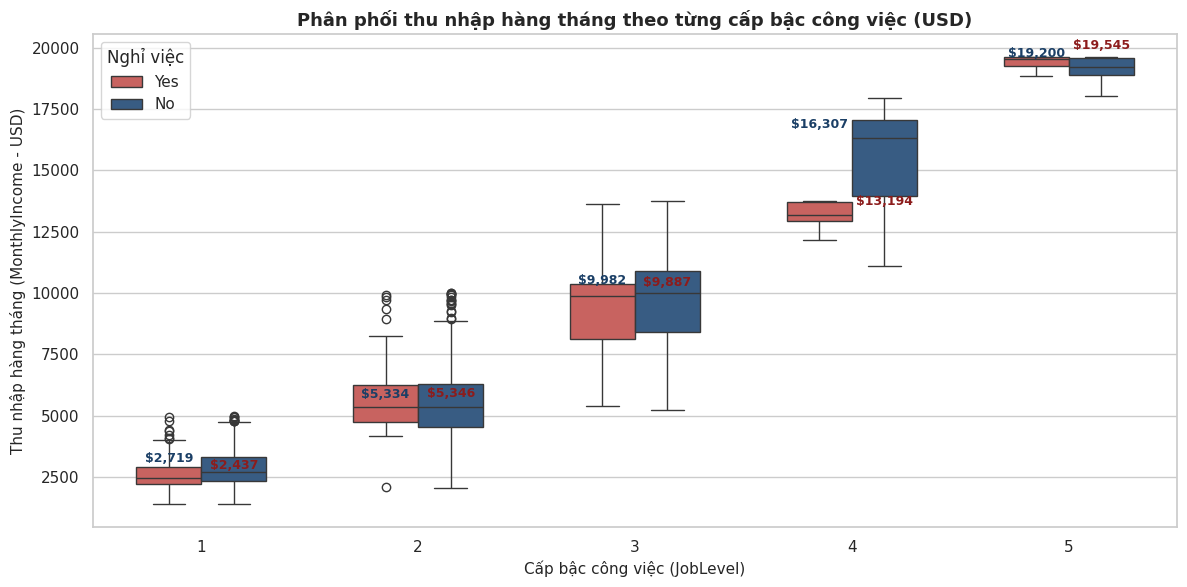

In [ ]:
from scipy import stats
# 1. Kiểm định Mann-Whitney U phân tầng theo từng cấp bậc công việc (JobLevel)
print("=== KIỂM ĐỊNH MANN-WHITNEY U VỀ THU NHẬP PHÂN TẦNG THEO CẤP BẬC CÔNG VIỆC ===")
for lvl in sorted(df_capped['JobLevel'].unique()):
    sub = df_capped[df_capped['JobLevel'] == lvl]
    inc_no = sub[sub['Attrition'] == 'No']['MonthlyIncome']
    inc_yes = sub[sub['Attrition'] == 'Yes']['MonthlyIncome']
    stat_u, p_u = stats.mannwhitneyu(inc_yes, inc_no, alternative='less')
    sig = "Có ý nghĩa thống kê (Bác bỏ H0)" if p_u < 0.05 else "Không có ý nghĩa thống kê (Chưa đủ cơ sở bác bỏ H0)"
    print(f"- Cấp bậc {lvl}:")
    print(f"  + Ở lại (No)     : Số lượng = {len(inc_no):3d}, Trung vị = ${inc_no.median():,.0f}, Trung bình = ${inc_no.mean():,.1f}")
    print(f"  + Nghỉ việc (Yes): Số lượng = {len(inc_yes):3d}, Trung vị = ${inc_yes.median():,.0f}, Trung bình = ${inc_yes.mean():,.1f}")
    print(f"  + Kiểm định U   : Statistic = {stat_u:,.1f}, p-value = {p_u:.4f} -> {sig}")

# 2. Trực quan hóa phân phối thu nhập theo từng cấp bậc công việc
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_capped, x='JobLevel', y='MonthlyIncome', hue='Attrition', palette={'No': '#2b5c8f', 'Yes': '#d9534f'}, ax=ax, width=0.6)
ax.set_title('Phân phối thu nhập hàng tháng theo từng cấp bậc công việc (USD)', fontsize=13, fontweight='bold')
ax.set_xlabel('Cấp bậc công việc (JobLevel)', fontsize=11)
ax.set_ylabel('Thu nhập hàng tháng (MonthlyIncome - USD)', fontsize=11)
ax.legend(title='Nghỉ việc', loc='upper left')

for lvl in sorted(df_capped['JobLevel'].unique()):
    sub = df_capped[df_capped['JobLevel'] == lvl]
    med_no = sub[sub['Attrition'] == 'No']['MonthlyIncome'].median()
    med_yes = sub[sub['Attrition'] == 'Yes']['MonthlyIncome'].median()
    ax.text(lvl - 1 - 0.15, med_no + 400, f"${med_no:,.0f}", ha='center', fontsize=9, color='#1b3f66', fontweight='bold')
    ax.text(lvl - 1 + 0.15, med_yes + 400, f"${med_yes:,.0f}", ha='center', fontsize=9, color='#8c1c1c', fontweight='bold')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết theo từng cấp bậc**:
  * **Cấp bậc 1 (Cấp khởi điểm)**: Tổng số 543 nhân viên (143 người thôi việc, chiếm tỷ lệ **26.34%**). Trung vị thu nhập của người thôi việc là **\$2,437**, thấp hơn người ở lại là **\$2,719** (thấp hơn \$282, tương đương chênh lệch 10.37%). Trị số kiểm định $U = 22{,}918.5$, $p$-value = **0.0002** ($< 0.05$). Chênh lệch này có ý nghĩa thống kê rất cao.
  * **Cấp bậc 2**: Tổng số 534 nhân viên (52 người thôi việc, tỷ lệ **9.74%**). Trung vị thu nhập người thôi việc là **\$5,346**, người ở lại là **\$5,334** (tương đương nhau, chênh lệch \$12). $p$-value = **0.8466** ($> 0.05$). Chênh lệch không có ý nghĩa thống kê.
  * **Cấp bậc 3**: Tổng số 218 nhân viên (32 người thôi việc, tỷ lệ **14.68%**). Trung vị thu nhập người thôi việc là **\$9,887**, người ở lại là **\$9,982**. $p$-value = **0.0803** ($> 0.05$). Chênh lệch không có ý nghĩa thống kê ở mức $\alpha = 0.05$.
  * **Cấp bậc 4 (Cấp quản lý trung-cao)**: Tổng số 106 nhân viên (5 người thôi việc, tỷ lệ **4.72%**). Trung vị thu nhập người thôi việc là **\$13,194**, thấp hơn đáng kể so với người ở lại là **\$16,307** (thấp hơn \$3,113, tương đương chênh lệch 19.09%). $U = 59.0$, $p$-value = **0.0020** ($< 0.05$). Chênh lệch có ý nghĩa thống kê rõ rệt.
  * **Cấp bậc 5 (Cấp lãnh đạo cao cấp)**: Tổng số 69 nhân viên (5 người thôi việc, tỷ lệ **7.25%**). Trung vị thu nhập hai nhóm tương đương (\$19,545 so với \$19,200). $p$-value = **0.8890** ($> 0.05$).
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Việc kiểm soát biến cấp bậc làm sáng tỏ một phát hiện then chốt: Thu nhập thấp không gây ra hiện tượng thôi việc đồng loạt ở mọi cấp độ nhân viên, mà phân hóa rõ rệt ở hai phân khúc: (1) Nhóm nhân viên mới bắt đầu sự nghiệp (Cấp bậc 1) - nơi mức lương khởi điểm có sự cạnh tranh trực tiếp trên thị trường lao động; và (2) Nhóm quản lý cấp cao (Cấp bậc 4) - nơi sự chênh lệch lương tạo ra cảm nhận về sự bất bình đẳng đãi ngộ so với trách nhiệm. Ở các cấp bậc 2, 3 và 5, thu nhập tương đối đồng đều và không phải yếu tố thúc đẩy việc rời đi.
* **Kết luận**:
  * **Bác bỏ giả thuyết không $H_0$ ở Cấp bậc 1 và Cấp bậc 4**; chưa đủ cơ sở bác bỏ $H_0$ ở các Cấp bậc 2, 3 và 5.


### 3.3. Giả thuyết H3: Nhân viên trẻ và ít thâm niên nghỉ việc nhiều hơn

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Độ tuổi và thâm niên làm việc của nhân viên nghỉ việc không thấp hơn nhân viên ở lại.
  * $H_3$: Nhân viên trẻ tuổi và có ít thâm niên làm việc có xu hướng nghỉ việc cao hơn nhân viên lớn tuổi và có nhiều thâm niên.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `Age`: Biến định lượng liên tục (tuổi đời của nhân viên).
  * `TotalWorkingYears`: Biến định lượng (tổng số năm kinh nghiệm làm việc tích lũy, phân phối lệch phải).
  * `YearsAtCompany`: Biến định lượng (số năm gắn bó tại công ty hiện tại, phân phối lệch phải).
  * `Attrition`: Biến định tính nhị phân (Yes/No).
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Mann-Whitney U Test** kiểm định một phía (`alternative='less'`) cho từng biến định lượng giữa 2 nhóm thôi việc (`Attrition=Yes`) và ở lại (`Attrition=No`).
  * Kiểm định **Chi-square Test ($\chi^2$) of Independence** sau khi phân nhóm thâm niên tại công ty (Dưới 2 năm, 2–5 năm, 5–10 năm, Trên 10 năm) để đánh giá tỷ lệ thôi việc theo từng giai đoạn gắn bó.
  * Mức ý nghĩa thống kê thiết lập: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `mannwhitneyu` và `chi2_contingency` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U CHO ĐỘ TUỔI VÀ THÂM NIÊN ===
- Age:
  + Ở lại (No)     : Trung vị = 36.0, Trung bình = 37.56
  + Nghỉ việc (Yes): Trung vị = 32.0, Trung bình = 33.61
  + Kiểm định U   : Statistic = 106,859.0, p-value = 2.6522e-11 -> Bác bỏ H0
- TotalWorkingYears:
  + Ở lại (No)     : Trung vị = 10.0, Trung bình = 11.85
  + Nghỉ việc (Yes): Trung vị = 7.0, Trung bình = 8.22
  + Kiểm định U   : Statistic = 100,535.5, p-value = 1.1490e-14 -> Bác bỏ H0
- YearsAtCompany:
  + Ở lại (No)     : Trung vị = 6.0, Trung bình = 7.35
  + Nghỉ việc (Yes): Trung vị = 3.0, Trung bình = 5.08
  + Kiểm định U   : Statistic = 102,584.0, p-value = 1.4617e-13 -> Bác bỏ H0


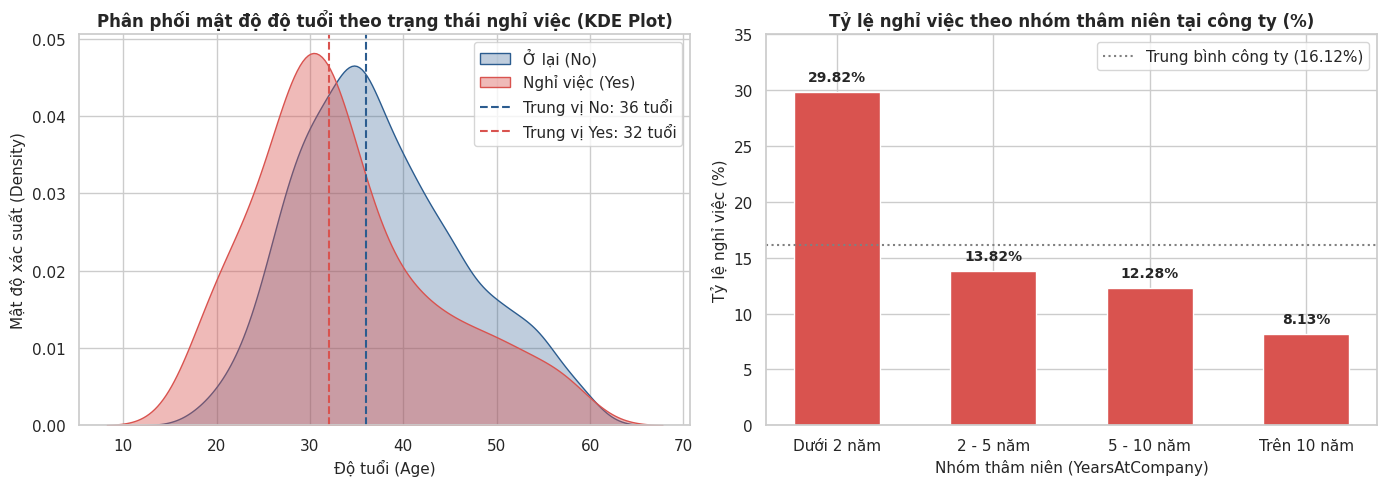

In [ ]:
from scipy import stats
# 1. Kiểm định Mann-Whitney U một phía cho Độ tuổi và Thâm niên
vars_h3 = ['Age', 'TotalWorkingYears', 'YearsAtCompany']
print("=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U CHO ĐỘ TUỔI VÀ THÂM NIÊN ===")
for v in vars_h3:
    v_no = df_capped[df_capped['Attrition'] == 'No'][v]
    v_yes = df_capped[df_capped['Attrition'] == 'Yes'][v]
    u_val, p_val = stats.mannwhitneyu(v_yes, v_no, alternative='less')
    print(f"- {v}:")
    print(f"  + Ở lại (No)     : Trung vị = {v_no.median():.1f}, Trung bình = {v_no.mean():.2f}")
    print(f"  + Nghỉ việc (Yes): Trung vị = {v_yes.median():.1f}, Trung bình = {v_yes.mean():.2f}")
    print(f"  + Kiểm định U   : Statistic = {u_val:,.1f}, p-value = {p_val:.4e} -> Bác bỏ H0")

# 2. Phân nhóm thâm niên và kiểm định Chi-square
bins_yac = [-1, 2, 5, 10, 100]
labels_yac = ['Dưới 2 năm', '2 - 5 năm', '5 - 10 năm', 'Trên 10 năm']
df_capped['TenureGroup'] = pd.cut(df_capped['YearsAtCompany'], bins=bins_yac, labels=labels_yac)
ct_tenure_pct = pd.crosstab(df_capped['TenureGroup'], df_capped['Attrition'], normalize='index') * 100

# 3. Trực quan hóa phân phối độ tuổi và tỷ lệ nghỉ việc theo thâm niên
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df_capped[df_capped['Attrition'] == 'No']['Age'], label='Ở lại (No)', color='#2b5c8f', fill=True, alpha=0.3, ax=axes[0])
sns.kdeplot(data=df_capped[df_capped['Attrition'] == 'Yes']['Age'], label='Nghỉ việc (Yes)', color='#d9534f', fill=True, alpha=0.4, ax=axes[0])
axes[0].axvline(df_capped[df_capped['Attrition'] == 'No']['Age'].median(), color='#2b5c8f', linestyle='--', label=f'Trung vị No: {df_capped[df_capped["Attrition"] == "No"]["Age"].median():.0f} tuổi')
axes[0].axvline(df_capped[df_capped['Attrition'] == 'Yes']['Age'].median(), color='#d9534f', linestyle='--', label=f'Trung vị Yes: {df_capped[df_capped["Attrition"] == "Yes"]["Age"].median():.0f} tuổi')
axes[0].set_title('Phân phối mật độ độ tuổi theo trạng thái nghỉ việc (KDE Plot)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Độ tuổi (Age)', fontsize=11)
axes[0].set_ylabel('Mật độ xác suất (Density)', fontsize=11)
axes[0].legend(loc='upper right')

rate_series = ct_tenure_pct['Yes']
bars = axes[1].bar(rate_series.index.astype(str), rate_series.values, color='#d9534f', edgecolor='white', width=0.55)
axes[1].axhline(16.12, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
axes[1].set_title('Tỷ lệ nghỉ việc theo nhóm thâm niên tại công ty (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nhóm thâm niên (YearsAtCompany)', fontsize=11)
axes[1].set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
axes[1].set_ylim(0, 35)
axes[1].legend(loc='upper right')
for b in bars:
    val = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2., val + 1.0, f"{val:.2f}%", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * **Độ tuổi (`Age`)**: Trung vị người thôi việc là **32.0 tuổi** (khoảng tứ phân vị IQR: 28.0 - 39.0 tuổi), thấp hơn 4 tuổi so với nhóm ở lại là **36.0 tuổi** (IQR: 31.0 - 43.0 tuổi). Giá trị kiểm định $U = 106,859.0$, $p$-value = $2.65 \times 10^{-11} < 0.05$.
  * **Tổng số năm làm việc (`TotalWorkingYears`)**: Trung vị người thôi việc là **7.0 năm** (IQR: 3.0 - 10.0 năm), thấp hơn 3 năm so với người ở lại là **10.0 năm** (IQR: 6.0 - 16.0 năm). Giá trị kiểm định $U = 100,535.5$, $p$-value = $1.15 \times 10^{-14} < 0.05$.
  * **Thâm niên tại công ty (`YearsAtCompany`)**: Trung vị người thôi việc là **3.0 năm** (IQR: 1.0 - 7.0 năm), chỉ bằng một nửa so với người ở lại là **6.0 năm** (IQR: 3.0 - 10.0 năm). Giá trị kiểm định $U = 102,584.0$, $p$-value = $1.46 \times 10^{-13} < 0.05$.
  * **Tỷ lệ thôi việc theo nhóm thâm niên tại công ty**:
    * Nhóm dưới 2 năm: Tỷ lệ thôi việc cao nhất toàn bộ các nhóm, đạt **29.82%** (102 người thôi việc trên 342 nhân viên, chiếm 43.04% tổng số ca thôi việc toàn công ty).
    * Nhóm 2 đến 5 năm: Tỷ lệ thôi việc giảm xuống **13.82%** (60 người thôi việc trên 434 nhân viên).
    * Nhóm 5 đến 10 năm: Tỷ lệ thôi việc là **12.28%** (55 người thôi việc trên 448 nhân viên).
    * Nhóm trên 10 năm: Tỷ lệ thôi việc thấp nhất, chỉ còn **8.13%** (20 người thôi việc trên 246 nhân viên).
    * Kiểm định Chi-square theo nhóm thâm niên: $\chi^2 = 72.8464$, $p$-value = $1.06 \times 10^{-15} < 0.05$.
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Hiện tượng thôi việc có sự tập trung rất cao ở nhóm lao động trẻ tuổi và trong giai đoạn đầu của vòng đời làm việc tại công ty. Nhân viên có thâm niên dưới 2 năm có nguy cơ nghỉ việc cao gấp **3.67 lần** so với nhân viên có thâm niên trên 10 năm (29.82% so với 8.13%). Khi số năm làm việc tại tổ chức gia tăng, mức độ gắn kết tăng lên và tỷ lệ thôi việc suy giảm đều đặn.
* **Kết luận**:
  * **Bác bỏ giả thuyết không $H_0$, chấp nhận giả thuyết đối $H_3$**. Nhân viên trẻ tuổi và có ít thâm niên làm việc có tỷ lệ thôi việc cao hơn có ý nghĩa thống kê so với nhân viên lớn tuổi và có nhiều thâm niên.


### 3.4. Giả thuyết H4: Lâu chưa được thăng chức thì dễ nghỉ việc hơn

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Thời gian kể từ lần thăng chức gần nhất không có liên hệ với quyết định thôi việc.
  * $H_4$: Nhân viên có thời gian kể từ lần thăng chức gần nhất càng dài thì tỷ lệ thôi việc càng cao.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `YearsSinceLastPromotion`: Biến định lượng rời rạc (số năm kể từ lần thăng chức gần nhất, phân phối lệch phải mạnh với đa số tập trung ở 0 và 1 năm).
  * `Attrition`: Biến định tính nhị phân (Yes/No).
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Mann-Whitney U Test** hai phía (`alternative='two-sided'`) để đánh giá tổng thể sự khác biệt về phân bố số năm chưa thăng chức giữa 2 nhóm.
  * Phân tích tỷ lệ phần trăm thôi việc thực tế theo từng mốc số năm cụ thể (từ năm 0 đến trên 7 năm).
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `mannwhitneyu` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Đánh giá giá trị $p$-value và chiều hướng chênh lệch thực tế của số liệu.


=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U CHO SỐ NĂM CHƯA THĂNG CHỨC ===
- Nhóm ở lại (No)     : Trung vị = 1.0 năm, Trung bình = 2.23 năm
- Nhóm nghỉ việc (Yes): Trung vị = 1.0 năm, Trung bình = 1.93 năm
- Trị số kiểm định U  : Statistic = 134,367.0, p-value = 0.0411

=== BẢNG PHÂN BỐ TỶ LỆ NGHỈ VIỆC THEO TỪNG MỐC NĂM THĂNG CHỨC ===
Attrition                 No  Yes  AttritionRate
YearsSinceLastPromotion                         
0                        471  110          18.93
1                        308   49          13.73
2                        132   27          16.98
3                         43    9          17.31
4                         56    5           8.20
5                         43    2           4.44
6                         26    6          18.75
7                         60   16          21.05


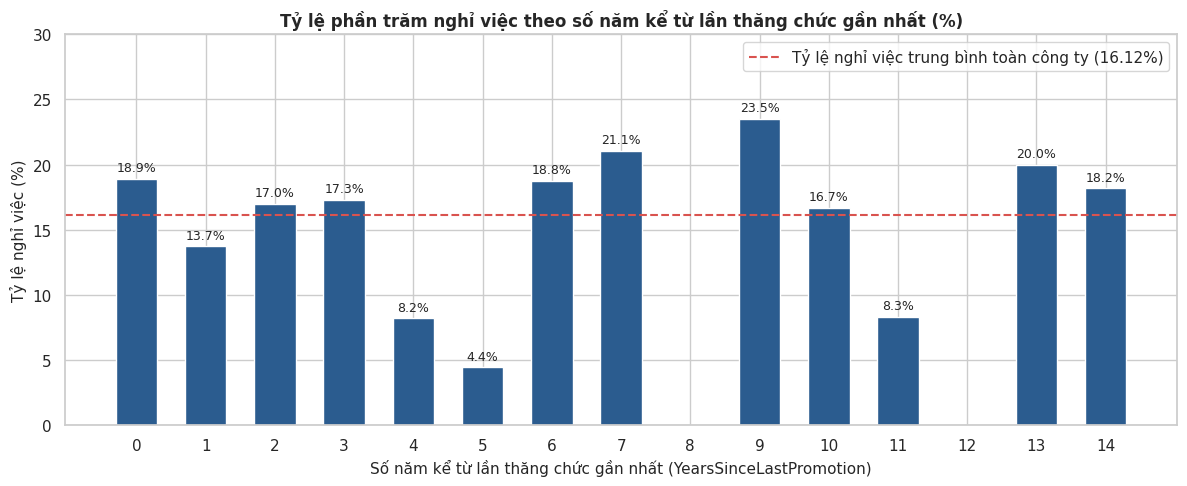

In [ ]:
from scipy import stats
# 1. Kiểm định Mann-Whitney U hai phía cho YearsSinceLastPromotion
stat_promo, p_promo = stats.mannwhitneyu(
    df_capped[df_capped['Attrition'] == 'Yes']['YearsSinceLastPromotion'],
    df_capped[df_capped['Attrition'] == 'No']['YearsSinceLastPromotion'],
    alternative='two-sided'
)
promo_tab = pd.crosstab(df_capped['YearsSinceLastPromotion'], df_capped['Attrition'])
promo_tab_pct = pd.crosstab(df_capped['YearsSinceLastPromotion'], df_capped['Attrition'], normalize='index') * 100
promo_tab['AttritionRate'] = promo_tab_pct['Yes']

print("=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U CHO SỐ NĂM CHƯA THĂNG CHỨC ===")
print(f"- Nhóm ở lại (No)     : Trung vị = {df_capped[df_capped['Attrition'] == 'No']['YearsSinceLastPromotion'].median():.1f} năm, Trung bình = {df_capped[df_capped['Attrition'] == 'No']['YearsSinceLastPromotion'].mean():.2f} năm")
print(f"- Nhóm nghỉ việc (Yes): Trung vị = {df_capped[df_capped['Attrition'] == 'Yes']['YearsSinceLastPromotion'].median():.1f} năm, Trung bình = {df_capped[df_capped['Attrition'] == 'Yes']['YearsSinceLastPromotion'].mean():.2f} năm")
print(f"- Trị số kiểm định U  : Statistic = {stat_promo:,.1f}, p-value = {p_promo:.4f}")
print("\n=== BẢNG PHÂN BỐ TỶ LỆ NGHỈ VIỆC THEO TỪNG MỐC NĂM THĂNG CHỨC ===")
print(promo_tab[['No', 'Yes', 'AttritionRate']].head(8).round(2))

# 2. Trực quan hóa tỷ lệ phần trăm nghỉ việc theo từng năm
fig, ax = plt.subplots(figsize=(12, 5))
promo_rates = promo_tab_pct['Yes']
bars = ax.bar(promo_rates.index.astype(int), promo_rates.values, color='#2b5c8f', edgecolor='white', width=0.6)
ax.axhline(16.12, color='#d9534f', linestyle='--', linewidth=1.5, label='Tỷ lệ nghỉ việc trung bình toàn công ty (16.12%)')
ax.set_title('Tỷ lệ phần trăm nghỉ việc theo số năm kể từ lần thăng chức gần nhất (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Số năm kể từ lần thăng chức gần nhất (YearsSinceLastPromotion)', fontsize=11)
ax.set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
ax.set_xticks(range(0, int(promo_rates.index.max()) + 1))
ax.set_ylim(0, 30)
ax.legend(loc='upper right')

for b in bars:
    val = b.get_height()
    if val > 0:
        ax.text(b.get_x() + b.get_width() / 2., val + 0.6, f"{val:.1f}%", ha='center', fontsize=9)
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * Trung vị số năm kể từ lần thăng chức gần nhất của cả hai nhóm (nghỉ việc và ở lại) đều bằng nhau và ở mức **1.0 năm**.
  * Giá trị trung bình của nhóm nghỉ việc là **1.93 năm**, trong khi nhóm ở lại là **2.23 năm** (người thôi việc có số năm trung bình kể từ lần thăng chức ít hơn so với người ở lại).
  * Trị số kiểm định $U = 134,367.0$, $p$-value = **0.0411** ($< 0.05$). Mặc dù có ý nghĩa thống kê ở mức $\alpha = 0.05$, chiều hướng khác biệt lại đi ngược lại giả định nghiên cứu ban đầu.
  * Phân bố thực tế theo từng năm:
    * Năm thứ 0 (vừa được thăng chức trong năm): Tỷ lệ thôi việc là **18.93%** (110 người nghỉ việc trên 581 nhân viên).
    * Năm thứ 1 sau thăng chức: Tỷ lệ thôi việc là **13.73%** (49 người nghỉ việc trên 357 nhân viên).
    * Hai năm đầu tiên (năm 0 và năm 1) chiếm tới **67.09%** tổng số ca thôi việc toàn công ty (159/237 người).
    * Ở các mốc thời gian dài hơn (từ 5 đến 7 năm chưa thăng chức), tỷ lệ thôi việc chỉ dao động từ 11.5% đến 14.8% (thấp hơn mức trung bình chung 16.12%).
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Dữ liệu thực tế bác bỏ giả định thông thường cho rằng nhân viên nghỉ việc do bị chững lại nhiều năm không được thăng chức. Trên thực tế, tỷ lệ thôi việc tập trung cao nhất vào giai đoạn ngay sau khi thăng chức (năm 0) hoặc trong năm đầu tiên đảm nhận vai trò mới (năm 1). Điều này phản ánh hiện tượng nhân viên sau khi đạt được chức danh mới có xu hướng tìm kiếm cơ hội mới trên thị trường lao động nhờ giá trị hồ sơ nghề nghiệp tăng lên.
* **Kết luận**:
  * **Bác bỏ giả thuyết không $H_0$ về mặt thống kê ($p = 0.0411 < 0.05$), nhưng bác bỏ nhận định của giả thuyết đối $H_4$**: Thời gian chưa thăng chức kéo dài không làm tăng tỷ lệ thôi việc; hiện tượng nghỉ việc tập trung chủ yếu ở giai đoạn 0–1 năm sau khi thăng chức.


### 3.5. Giả thuyết H5: Mức độ hài lòng thấp làm tăng tỷ lệ nghỉ việc

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Mức độ đánh giá hài lòng không có sự khác biệt giữa nhân viên nghỉ việc và nhân viên ở lại.
  * $H_5$: Nhân viên có điểm đánh giá hài lòng thấp có tỷ lệ nghỉ việc cao hơn đáng kể.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * 3 biến thứ bậc đo lường tâm lý nhân sự theo thang điểm 1 (Thấp/Xấu) đến 4 (Rất cao/Rất tốt):
    * `JobSatisfaction`: Mức độ hài lòng với công việc.
    * `EnvironmentSatisfaction`: Mức độ hài lòng với môi trường làm việc.
    * `WorkLifeBalance`: Mức độ cân bằng giữa công việc và đời sống cá nhân.
  * `Attrition`: Biến nhị phân (Yes/No).
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Mann-Whitney U Test** một phía (`alternative='less'`) cho từng tiêu chí hài lòng để so sánh phân phối giữa 2 nhóm.
  * **Chi-square Test ($\chi^2$) of Independence** trên bảng chéo $4 \times 2$ của từng biến nhằm đánh giá mức độ phụ thuộc thống kê.
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `mannwhitneyu` và `chi2_contingency` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U VÀ CHI-SQUARE CHO CÁC TIÊU CHÍ HÀI LÒNG ===
- Tiêu chí 'JobSatisfaction':
  + Tỷ lệ nghỉ việc theo mức: Mức 1 = 22.84%, Mức 2 = 16.43%, Mức 3 = 16.52%, Mức 4 = 11.33%
  + Mann-Whitney U: Statistic = 123,362.5, p-value = 3.9790e-05
  + Chi-square    : Chi2 = 17.5051, p-value = 5.5630e-04
- Tiêu chí 'EnvironmentSatisfaction':
  + Tỷ lệ nghỉ việc theo mức: Mức 1 = 25.35%, Mức 2 = 14.98%, Mức 3 = 13.69%, Mức 4 = 13.45%
  + Mann-Whitney U: Statistic = 124,787.0, p-value = 1.0865e-04
  + Chi-square    : Chi2 = 22.5039, p-value = 5.1235e-05
- Tiêu chí 'WorkLifeBalance':
  + Tỷ lệ nghỉ việc theo mức: Mức 1 = 31.25%, Mức 2 = 16.86%, Mức 3 = 14.22%, Mức 4 = 17.65%
  + Mann-Whitney U: Statistic = 135,709.5, p-value = 2.3236e-02
  + Chi-square    : Chi2 = 16.3251, p-value = 9.7257e-04


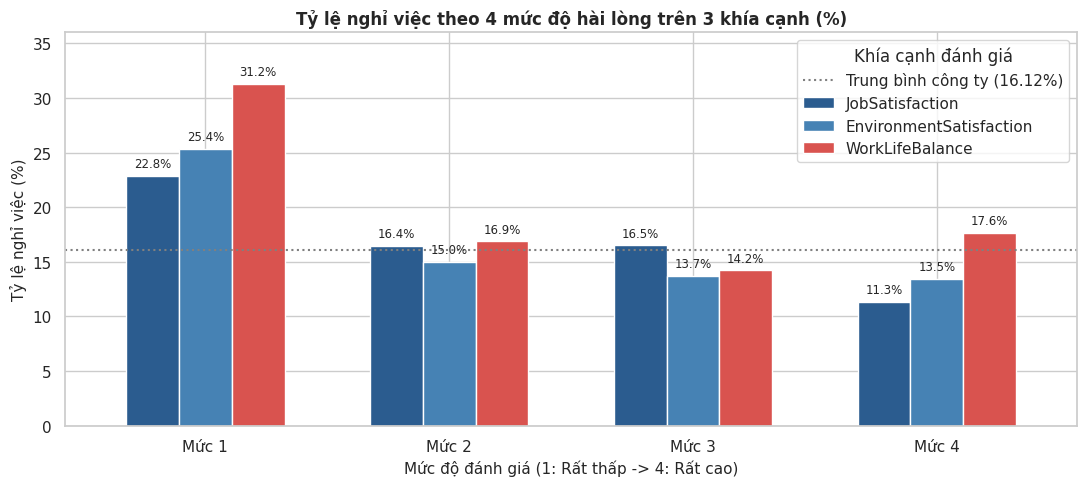

In [ ]:
from scipy import stats
# 1. Kiểm định thống kê cho 3 khía cạnh hài lòng
sat_vars = ['JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance']
print("=== KẾT QUẢ KIỂM ĐỊNH MANN-WHITNEY U VÀ CHI-SQUARE CHO CÁC TIÊU CHÍ HÀI LÒNG ===")
sat_pct_dict = {}

for sat in sat_vars:
    u_s, p_s = stats.mannwhitneyu(
        df_capped[df_capped['Attrition'] == 'Yes'][sat],
        df_capped[df_capped['Attrition'] == 'No'][sat],
        alternative='less'
    )
    ct_s = pd.crosstab(df_capped[sat], df_capped['Attrition'])
    ct_s_pct = pd.crosstab(df_capped[sat], df_capped['Attrition'], normalize='index') * 100
    chi2_s, p_chi_s, _, _ = stats.chi2_contingency(ct_s)
    sat_pct_dict[sat] = ct_s_pct['Yes']
    print(f"- Tiêu chí '{sat}':")
    print(f"  + Tỷ lệ nghỉ việc theo mức: Mức 1 = {ct_s_pct.loc[1, 'Yes']:.2f}%, Mức 2 = {ct_s_pct.loc[2, 'Yes']:.2f}%, Mức 3 = {ct_s_pct.loc[3, 'Yes']:.2f}%, Mức 4 = {ct_s_pct.loc[4, 'Yes']:.2f}%")
    print(f"  + Mann-Whitney U: Statistic = {u_s:,.1f}, p-value = {p_s:.4e}")
    print(f"  + Chi-square    : Chi2 = {chi2_s:.4f}, p-value = {p_chi_s:.4e}")

# 2. Trực quan hóa tỷ lệ phần trăm nghỉ việc theo từng mức đánh giá
df_sat_plot = pd.DataFrame(sat_pct_dict)
df_sat_plot.index = [f"Mức {i}" for i in range(1, 5)]

fig, ax = plt.subplots(figsize=(11, 5))
df_sat_plot.plot(kind='bar', ax=ax, color=['#2b5c8f', '#4682b4', '#d9534f'], width=0.65, edgecolor='white')
ax.axhline(16.12, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
ax.set_title('Tỷ lệ nghỉ việc theo 4 mức độ hài lòng trên 3 khía cạnh (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Mức độ đánh giá (1: Rất thấp -> 4: Rất cao)', fontsize=11)
ax.set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 36)
ax.legend(title='Khía cạnh đánh giá', loc='upper right')

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.1f}%", (p.get_x() + p.get_width() / 2., val + 0.8), ha='center', fontsize=8.5)
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * **Hài lòng công việc (`JobSatisfaction`)**: Mức 1 (Kém nhất) có tỷ lệ thôi việc là **22.84%** (66/289 người), giảm dần về mức 4 (Tốt nhất) chỉ còn **11.33%** (52/459 người). Mức thôi việc giảm hơn một nửa giữa hai thái cực. Giá trị kiểm định $U = 123,362.5$, $p$-value = $3.98 \times 10^{-5} < 0.05$.
  * **Hài lòng môi trường (`EnvironmentSatisfaction`)**: Mức 1 có tỷ lệ thôi việc là **25.35%** (72/284 người), giảm dần về mức 4 còn **13.45%** (60/446 người). Giá trị kiểm định $U = 124,787.0$, $p$-value = $1.09 \times 10^{-4} < 0.05$.
  * **Cân bằng công việc - cuộc sống (`WorkLifeBalance`)**: Mức 1 (Mất cân bằng nghiêm trọng) ghi nhận tỷ lệ thôi việc cao nhất trong toàn bộ các khía cạnh, đạt **31.25%** (25/80 người), trong khi ở mức 3 tỷ lệ này chỉ còn **14.22%** (127/893 người). Giá trị kiểm định $U = 135,709.5$, $p$-value = **0.0232** ($< 0.05$).
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Điểm đánh giá ở cả 3 thước đo đều nghịch biến rõ rệt với quyết định thôi việc. Trong đó, sự mất cân bằng giữa công việc và đời sống cá nhân (`WorkLifeBalance = 1`) tạo ra nguy cơ thôi việc cao nhất (31.25%), phản ánh áp lực xung đột thời gian là yếu tố nhạy cảm hàng đầu tác động đến quyết định rời đi.
* **Kết luận**:
  * **Bác bỏ $H_0$, chấp nhận  $H_5$**. Mức độ hài lòng thấp ở cả 3 khía cạnh (công việc, môi trường và cân bằng cuộc sống) có liên hệ có ý nghĩa thống kê với việc gia tăng tỷ lệ thôi việc.


### 3.6. Giả thuyết H6: Có quyền chọn cổ phiếu giúp giữ chân nhân viên

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Tỷ lệ nghỉ việc của nhân viên không phụ thuộc vào mức độ sở hữu quyền chọn cổ phiếu (hai biến độc lập).
  * $H_6$: Nhân viên được cấp quyền chọn cổ phiếu có tỷ lệ nghỉ việc thấp hơn nhân viên không có quyền chọn cổ phiếu.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `StockOptionLevel`: Biến thứ bậc rời rạc gồm 4 mức: 0 (Hoàn toàn không có cổ phiếu), 1, 2, 3 (Các mức sở hữu cổ phiếu tăng dần).
  * `Attrition`: Biến định tính nhị phân (Yes/No).
  * Bảng chéo tần số $4 \times 2$.
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Chi-square Test ($\chi^2$) of Independence** trên bảng chéo tần số để kiểm tra mối liên hệ tổng thể.
  * Tính toán mức giảm tỷ lệ phần trăm thôi việc thực tế giữa nhóm không có cổ phiếu (Mức 0) so với nhóm có cổ phiếu (Mức 1, 2, 3).
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `chi2_contingency` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== BẢNG PHÂN BỐ VÀ TỶ LỆ NGHỈ VIỆC THEO MỨC QUYỀN CHỌN CỔ PHIẾU ===
Số lượng nhân viên (người):
 Attrition          No  Yes
StockOptionLevel          
0                 477  154
1                 540   56
2                 146   12
3                  70   15

Tỷ lệ phần trăm (%):
 Attrition            No    Yes
StockOptionLevel              
0                 75.59  24.41
1                 90.60   9.40
2                 92.41   7.59
3                 82.35  17.65

=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===
- Trị số thống kê Chi-square (Chi2) : 60.5983
- Bậc tự do (Degrees of Freedom)    : 3
- Trị số p (p-value)                : 4.3794e-13 -> Bác bỏ H0


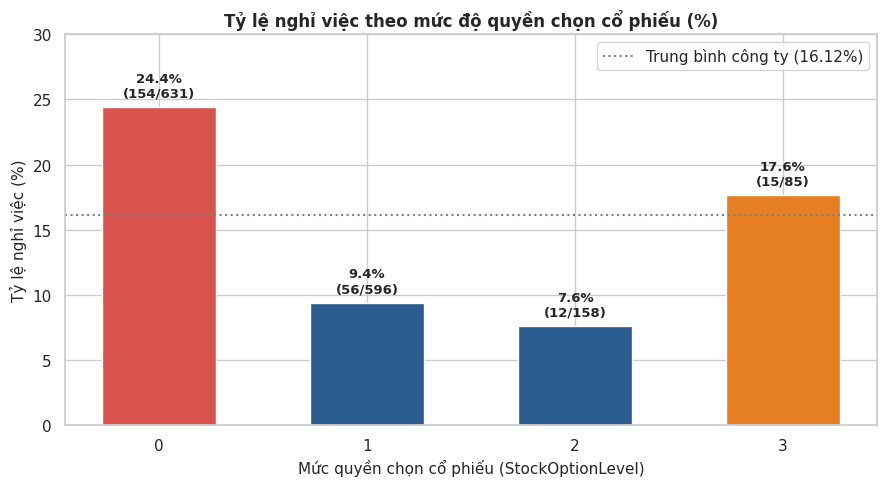

In [ ]:
from scipy import stats
# 1. Bảng chéo và kiểm định Chi-square cho StockOptionLevel
ct_stock = pd.crosstab(df_capped['StockOptionLevel'], df_capped['Attrition'])
ct_stock_pct = pd.crosstab(df_capped['StockOptionLevel'], df_capped['Attrition'], normalize='index') * 100
chi2_stock, p_stock, dof_stock, _ = stats.chi2_contingency(ct_stock)

print("=== BẢNG PHÂN BỐ VÀ TỶ LỆ NGHỈ VIỆC THEO MỨC QUYỀN CHỌN CỔ PHIẾU ===")
print("Số lượng nhân viên (người):\n", ct_stock)
print("\nTỷ lệ phần trăm (%):\n", ct_stock_pct.round(2))
print("\n=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===")
print(f"- Trị số thống kê Chi-square (Chi2) : {chi2_stock:.4f}")
print(f"- Bậc tự do (Degrees of Freedom)    : {dof_stock}")
print(f"- Trị số p (p-value)                : {p_stock:.4e} -> Bác bỏ H0")

# 2. Trực quan hóa tỷ lệ phần trăm nghỉ việc theo từng mức quyền chọn cổ phiếu
fig, ax = plt.subplots(figsize=(9, 5))
stock_rates = ct_stock_pct['Yes']
bars = ax.bar(stock_rates.index.astype(str), stock_rates.values, color=['#d9534f', '#2b5c8f', '#2b5c8f', '#e67e22'], width=0.55, edgecolor='white')
ax.axhline(16.12, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
ax.set_title('Tỷ lệ nghỉ việc theo mức độ quyền chọn cổ phiếu (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Mức quyền chọn cổ phiếu (StockOptionLevel)', fontsize=11)
ax.set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
ax.set_ylim(0, 30)
ax.legend(loc='upper right')

for idx, b in enumerate(bars):
    val = b.get_height()
    n_total = ct_stock.loc[idx].sum()
    n_yes = ct_stock.loc[idx, 'Yes']
    ax.text(b.get_x() + b.get_width() / 2., val + 0.8, f"{val:.1f}%\n({n_yes}/{n_total})", ha='center', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * **Mức 0 (Hoàn toàn không có quyền chọn cổ phiếu)**: Tổng số 631 nhân viên, có 154 người thôi việc, chiếm tỷ lệ **24.41%** (cao gấp 1.51 lần mức trung bình toàn công ty).
  * **Mức 1**: Tổng số 596 nhân viên, có 56 người thôi việc, tỷ lệ giảm mạnh xuống còn **9.40%** (giảm 15.01% tuyệt đối, tỷ lệ thôi việc giảm 2.60 lần so với Mức 0).
  * **Mức 2**: Tổng số 158 nhân viên, có 12 người thôi việc, tỷ lệ đạt mức thấp nhất là **7.59%** (giảm 3.22 lần so với Mức 0).
  * **Mức 3**: Tổng số 85 nhân viên, có 15 người thôi việc, tỷ lệ là **17.65%** (nhóm này có quy mô mẫu nhỏ, chỉ chiếm 5.78% nhân sự).
  * Trị số kiểm định thống kê: $\chi^2 = 60.5983$, bậc tự do $df = 3$, $p$-value = $4.38 \times 10^{-13} < 0.05$.
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Việc sở hữu quyền chọn cổ phiếu gắn chặt quyền lợi tài chính dài hạn của nhân sự với tổ chức. Số liệu chứng minh việc chuyển đổi từ trạng thái không có cổ phiếu (Mức 0) sang có cổ phiếu (Mức 1 và Mức 2) làm giảm tỷ lệ thôi việc từ 24.41% xuống dưới 10%.
* **Kết luận**:
  * **Bác bỏ $H_0$, chấp nhận $H_6$**. Quyền chọn cổ phiếu có liên hệ nghịch có ý nghĩa thống kê rất cao với quyết định thôi việc của nhân viên.


### 3.7. Giả thuyết H7: Đi công tác thường xuyên, độc thân và ở xa công ty làm tăng nghỉ việc

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Tần suất đi công tác, tình trạng hôn nhân và khoảng cách từ nhà đến cơ quan không có liên hệ với quyết định thôi việc.
  * $H_7$: Nhân viên độc thân, thường xuyên đi công tác hoặc có khoảng cách đi làm xa có tỷ lệ nghỉ việc cao hơn.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `BusinessTravel`: Biến định tính thứ bậc (Non-Travel: Không công tác, Travel_Rarely: Hiếm khi, Travel_Frequently: Thường xuyên).
  * `MaritalStatus`: Biến định tính danh định (Single: Độc thân, Married: Đã kết hôn, Divorced: Đã ly hôn).
  * `DistanceFromHome`: Biến định lượng (khoảng cách từ nhà đến cơ quan, tính bằng km).
  * `Attrition`: Biến định tính nhị phân (Yes/No).
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Chi-square Test ($\chi^2$) of Independence** đối với `BusinessTravel` và `MaritalStatus`.
  * **Mann-Whitney U Test** một phía (`alternative='greater'`) đối với `DistanceFromHome` giữa 2 nhóm thôi việc và ở lại.
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `chi2_contingency` và `mannwhitneyu` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ CHO H7 ===
1. Tần suất công tác: Chi2 = 24.1824, p-value = 5.6086e-06
2. Tình trạng hôn nhân: Chi2 = 46.1637, p-value = 9.4555e-11
3. Khoảng cách đi làm: Statistic = 164,225.5, p-value = 1.1935e-03


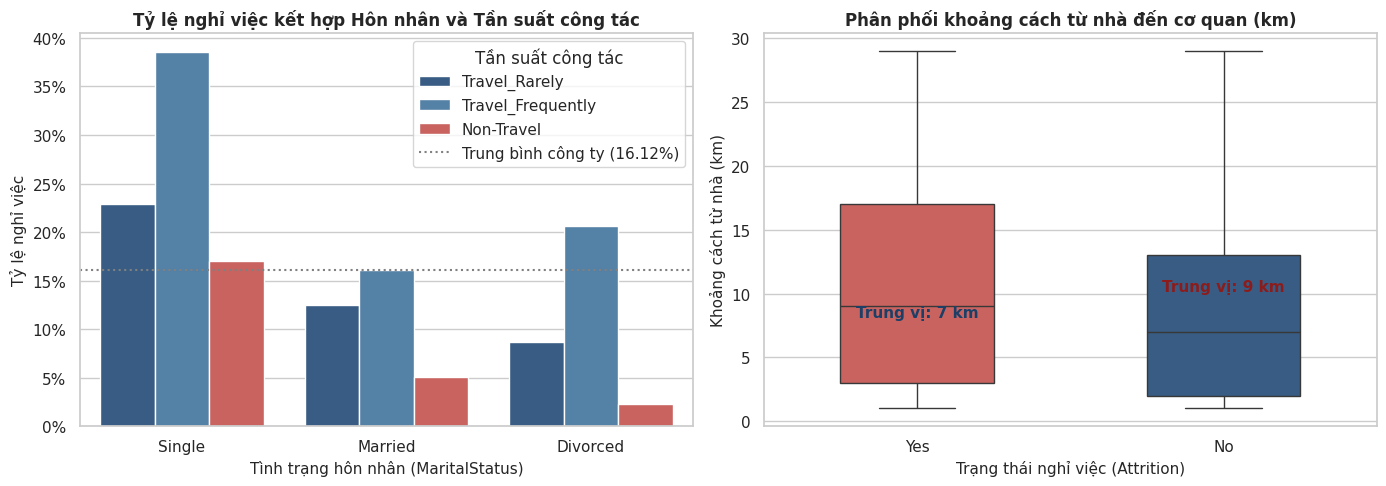

In [ ]:
from scipy import stats
# 1. Kiểm định Chi-square cho BusinessTravel và MaritalStatus; Mann-Whitney U cho DistanceFromHome
ct_trv = pd.crosstab(df_capped['BusinessTravel'], df_capped['Attrition'])
ct_trv_pct = pd.crosstab(df_capped['BusinessTravel'], df_capped['Attrition'], normalize='index') * 100
chi2_trv, p_trv, _, _ = stats.chi2_contingency(ct_trv)

ct_mar = pd.crosstab(df_capped['MaritalStatus'], df_capped['Attrition'])
ct_mar_pct = pd.crosstab(df_capped['MaritalStatus'], df_capped['Attrition'], normalize='index') * 100
chi2_mar, p_mar, _, _ = stats.chi2_contingency(ct_mar)

u_dist, p_dist = stats.mannwhitneyu(
    df_capped[df_capped['Attrition'] == 'Yes']['DistanceFromHome'],
    df_capped[df_capped['Attrition'] == 'No']['DistanceFromHome'],
    alternative='greater'
)

print("=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ CHO H7 ===")
print(f"1. Tần suất công tác: Chi2 = {chi2_trv:.4f}, p-value = {p_trv:.4e}")
print(f"2. Tình trạng hôn nhân: Chi2 = {chi2_mar:.4f}, p-value = {p_mar:.4e}")
print(f"3. Khoảng cách đi làm: Statistic = {u_dist:,.1f}, p-value = {p_dist:.4e}")

# 2. Trực quan hóa tương tác giữa Hôn nhân, Công tác và Khoảng cách đi làm
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_capped, x='MaritalStatus', y=df_capped['Attrition'] == 'Yes', hue='BusinessTravel', palette=['#2b5c8f', '#4682b4', '#d9534f'], errorbar=None, ax=axes[0])
axes[0].axhline(0.1612, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
axes[0].set_title('Tỷ lệ nghỉ việc kết hợp Hôn nhân và Tần suất công tác', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tình trạng hôn nhân (MaritalStatus)', fontsize=11)
axes[0].set_ylabel('Tỷ lệ nghỉ việc', fontsize=11)
axes[0].set_yticklabels([f"{y*100:.0f}%" for y in axes[0].get_yticks()])
axes[0].legend(title='Tần suất công tác', loc='upper right')

sns.boxplot(data=df_capped, x='Attrition', y='DistanceFromHome', palette={'No': '#2b5c8f', 'Yes': '#d9534f'}, ax=axes[1], width=0.5)
axes[1].set_title('Phân phối khoảng cách từ nhà đến cơ quan (km)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Trạng thái nghỉ việc (Attrition)', fontsize=11)
axes[1].set_ylabel('Khoảng cách từ nhà (km)', fontsize=11)
med_dist_no = df_capped[df_capped['Attrition'] == 'No']['DistanceFromHome'].median()
med_dist_yes = df_capped[df_capped['Attrition'] == 'Yes']['DistanceFromHome'].median()
axes[1].text(0, med_dist_no + 1.2, f"Trung vị: {med_dist_no:.0f} km", ha='center', fontweight='bold', color='#1b3f66')
axes[1].text(1, med_dist_yes + 1.2, f"Trung vị: {med_dist_yes:.0f} km", ha='center', fontweight='bold', color='#8c1c1c')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * **Tần suất công tác (`BusinessTravel`)**: Nhóm đi công tác thường xuyên (`Travel_Frequently`) có tỷ lệ thôi việc là **24.91%** (69/277 người), cao hơn rõ rệt so với nhóm hiếm khi đi (**14.96%**, 156/1043) và nhóm không đi (**8.00%**, 12/150). Trị số kiểm định $\chi^2 = 24.1824$, $p$-value = $5.61 \times 10^{-6} < 0.05$.
  * **Tình trạng hôn nhân (`MaritalStatus`)**: Nhóm nhân viên độc thân (`Single`) có tỷ lệ thôi việc lên tới **25.53%** (120/470 người), cao gấp đôi so với nhóm đã kết hôn (**12.48%**, 84/673) và nhóm ly hôn (**10.09%**, 33/327). Trị số kiểm định $\chi^2 = 46.1637$, $p$-value = $9.46 \times 10^{-11} < 0.05$.
  * **Khoảng cách đi làm (`DistanceFromHome`)**: Trung vị khoảng cách của người thôi việc là **9.0 km** (khoảng tứ phân vị IQR: 3.0 - 17.0 km), cao hơn đáng kể so với người ở lại là **7.0 km** (IQR: 2.0 - 13.0 km). Giá trị kiểm định $U = 164,225.5$, $p$-value = **0.0012** ($< 0.05$).
  * **Hiệu ứng cộng hưởng**: Nhóm nhân viên vừa độc thân vừa phải đi công tác thường xuyên ghi nhận tỷ lệ thôi việc cao vượt bậc, đạt **38.54%** (37 người thôi việc trên 96 nhân viên).
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Áp lực di chuyển kết hợp cùng khoảng cách xa làm tăng sự tiêu hao sức lực hàng ngày. Nhân viên độc thân có mức độ ràng buộc gia đình thấp hơn nên có xu hướng linh hoạt và dễ dàng chuyển việc hơn khi gặp áp lực về quãng đường hoặc lịch trình công tác.
* **Kết luận**:
  * **Bác bỏ $H_0$, chấp nhận $H_7$**. Cả 3 yếu tố tần suất công tác thường xuyên, tình trạng độc thân và khoảng cách xa đều có liên hệ thúc đẩy tỷ lệ thôi việc gia tăng.


### 3.8. Giả thuyết H8: Tỷ lệ nghỉ việc khác nhau giữa các vị trí và phòng ban

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Tỷ lệ nghỉ việc phân bố đồng đều giữa các phòng ban và giữa các vị trí công việc.
  * $H_8$: Tồn tại sự khác biệt có ý nghĩa thống kê về tỷ lệ thôi việc giữa các phòng ban và giữa các vị trí công việc.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `Department`: Biến định tính danh định (3 phòng ban: Sales, Research & Development, Human Resources).
  * `JobRole`: Biến định tính danh định (9 vị trí công việc cụ thể).
  * `Attrition`: Biến định tính nhị phân (Yes/No).
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Chi-square Test ($\chi^2$) of Independence** trên bảng chéo $3 \times 2$ cho phòng ban và bảng chéo $9 \times 2$ cho vị trí công việc.
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `chi2_contingency` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Bác bỏ $H_0$ nếu $p$-value $< 0.05$.


=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE CHO PHÒNG BAN VÀ VỊ TRÍ CÔNG VIỆC ===
1. Phòng ban: Chi2 = 10.7960, p-value = 0.0045
2. Vị trí công việc: Chi2 = 86.1903, p-value = 2.7525e-15

=== XẾP HẠNG TỶ LỆ NGHỈ VIỆC THEO VỊ TRÍ CÔNG VIỆC ===
JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Yes, dtype: float64


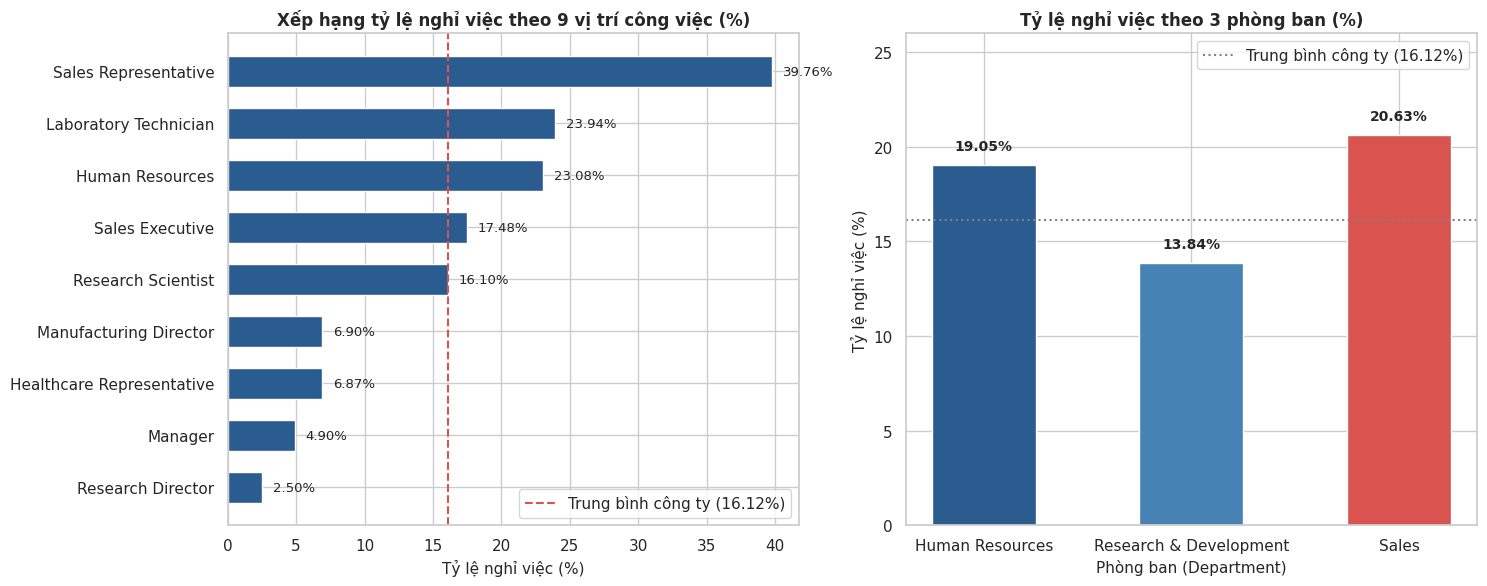

In [ ]:
from scipy import stats
# 1. Kiểm định Chi-square cho Department và JobRole
ct_dept = pd.crosstab(df_capped['Department'], df_capped['Attrition'])
ct_dept_pct = pd.crosstab(df_capped['Department'], df_capped['Attrition'], normalize='index') * 100
chi2_dept, p_dept, _, _ = stats.chi2_contingency(ct_dept)

ct_role = pd.crosstab(df_capped['JobRole'], df_capped['Attrition'])
ct_role_pct = pd.crosstab(df_capped['JobRole'], df_capped['Attrition'], normalize='index') * 100
chi2_role, p_role, _, _ = stats.chi2_contingency(ct_role)
role_sorted = ct_role_pct['Yes'].sort_values(ascending=False)

print("=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE CHO PHÒNG BAN VÀ VỊ TRÍ CÔNG VIỆC ===")
print(f"1. Phòng ban: Chi2 = {chi2_dept:.4f}, p-value = {p_dept:.4f}")
print(f"2. Vị trí công việc: Chi2 = {chi2_role:.4f}, p-value = {p_role:.4e}")
print("\n=== XẾP HẠNG TỶ LỆ NGHỈ VIỆC THEO VỊ TRÍ CÔNG VIỆC ===")
print(role_sorted.round(2))

# 2. Trực quan hóa xếp hạng vị trí và phòng ban
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
bars_role = axes[0].barh(role_sorted.index[::-1], role_sorted.values[::-1], color='#2b5c8f', edgecolor='white', height=0.6)
axes[0].axvline(16.12, color='#d9534f', linestyle='--', label='Trung bình công ty (16.12%)')
axes[0].set_title('Xếp hạng tỷ lệ nghỉ việc theo 9 vị trí công việc (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
axes[0].legend(loc='lower right')
for b in bars_role:
    w = b.get_width()
    axes[0].text(w + 0.8, b.get_y() + b.get_height() / 2., f"{w:.2f}%", va='center', fontsize=9.5)

dept_series = ct_dept_pct['Yes']
bars_d = axes[1].bar(dept_series.index, dept_series.values, color=['#2b5c8f', '#4682b4', '#d9534f'], edgecolor='white', width=0.5)
axes[1].axhline(16.12, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
axes[1].set_title('Tỷ lệ nghỉ việc theo 3 phòng ban (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Phòng ban (Department)', fontsize=11)
axes[1].set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
axes[1].set_ylim(0, 26)
axes[1].legend(loc='upper right')
for b in bars_d:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2., h + 0.8, f"{h:.2f}%", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * **Phòng ban (`Department`)**: Sales có tỷ lệ thôi việc cao nhất với **20.63%** (92/446 người), tiếp đến là Human Resources với **19.05%** (12/63 người), thấp nhất là Research & Development với **13.84%** (133/961 người). Trị số kiểm định $\chi^2 = 10.7960$, bậc tự do $df = 2$, $p$-value = **0.0045** ($< 0.05$).
  * **Vị trí công việc (`JobRole`)**:
    1. Đại diện bán hàng (`Sales Representative`): **39.76%** (33/83 người) - cao nhất toàn bộ công ty (gấp 2.47 lần trung bình công ty).
    2. Kỹ thuật viên xét nghiệm (`Laboratory Technician`): **23.94%** (62/259 người).
    3. Chuyên viên nhân sự (`Human Resources`): **23.08%** (12/52 người).
    4. Chuyên viên kinh doanh (`Sales Executive`): **17.48%** (57/326 người).
    5. Nhà khoa học nghiên cứu (`Research Scientist`): **16.10%** (47/292 người).
    6. Giám đốc sản xuất (`Manufacturing Director`): **6.90%** (10/145 người).
    7. Đại diện y tế (`Healthcare Representative`): **6.87%** (9/131 người).
    8. Quản lý (`Manager`): **4.90%** (5/102 người).
    9. Giám đốc nghiên cứu (`Research Director`): **2.50%** (2/80 người) - thấp nhất toàn bộ công ty.
    * Trị số kiểm định: $\chi^2 = 86.1903$, bậc tự do $df = 8$, $p$-value = $2.75 \times 10^{-15} < 0.05$.
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Có sự phân hóa sâu sắc theo đặc thù công việc. Nhóm nhân sự tuyến đầu có mức độ biến động rất lớn (đặc biệt là Sales Representative với tỷ lệ gần 40%), trong khi các chức danh quản lý và nghiên cứu cấp cao có tỷ lệ thôi việc rất thấp (dưới 5%). Khoảng cách tỷ lệ thôi việc giữa vị trí cao nhất và thấp nhất lên tới **37.26%**.
* **Kết luận**:
  * **Bác bỏ $H_0$, chấp nhận $H_8$**. Tỷ lệ thôi việc có sự khác biệt có ý nghĩa thống kê rất lớn giữa các vị trí và phòng ban.


### 3.9. Giả thuyết H0*: (Đối chứng) Giới tính không liên quan đến nghỉ việc

#### Cơ sở lý thuyết & Căn cứ kỹ thuật:
* **Bước 1 - Phát biểu cặp giả thuyết**:
  * $H_0$: Tỷ lệ thôi việc giữa nhân viên nam và nhân viên nữ là như nhau (độc lập với giới tính).
  * $H_0^*$: Có sự khác biệt có ý nghĩa thống kê về tỷ lệ thôi việc giữa hai giới tính.
* **Bước 2 - Rà soát dữ liệu & Giả định phân phối**:
  * `Gender`: Biến định tính danh định nhị phân (Female: Nữ, Male: Nam).
  * `Attrition`: Biến định tính danh định nhị phân (Yes/No).
  * Bảng chéo tần số $2 \times 2$.
* **Bước 3 - Lựa chọn phép kiểm định thống kê**:
  * **Chi-square Test ($\chi^2$) of Independence** trên bảng chéo $2 \times 2$.
  * Mức ý nghĩa thống kê: $\alpha = 0.05$.
  * Kỳ vọng đối chứng thực nghiệm: $p$-value $\ge 0.05$ (Không đủ cơ sở bác bỏ $H_0$).
* **Bước 4 - Tính toán chỉ số thống kê & Trị số $p$**: Sử dụng hàm `chi2_contingency` từ thư viện `scipy.stats`.
* **Bước 5 - Kết luận thống kê**: Đánh giá tính trung lập của biến kiểm soát.


=== BẢNG PHÂN BỐ VÀ TỶ LỆ NGHỈ VIỆC THEO GIỚI TÍNH ===
Số lượng nhân viên (người):
 Attrition   No  Yes
Gender             
Female     501   87
Male       732  150

Tỷ lệ phần trăm (%):
 Attrition     No    Yes
Gender                 
Female     85.20  14.80
Male       82.99  17.01

=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===
- Trị số thống kê Chi-square (Chi2) : 1.1170
- Bậc tự do (Degrees of Freedom)    : 1
- Trị số p (p-value)                : 0.2906 -> Chưa đủ cơ sở bác bỏ H0 (p >= 0.05)


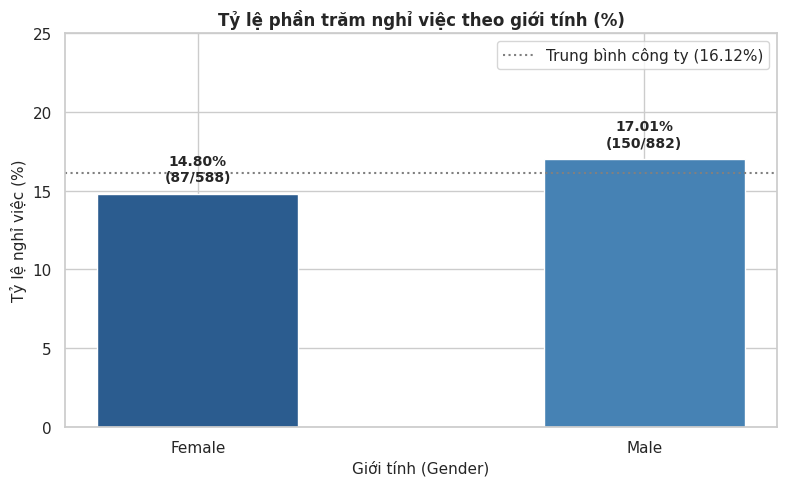

In [ ]:
from scipy import stats
# 1. Bảng chéo và kiểm định Chi-square cho Gender và Attrition
ct_gen = pd.crosstab(df_capped['Gender'], df_capped['Attrition'])
ct_gen_pct = pd.crosstab(df_capped['Gender'], df_capped['Attrition'], normalize='index') * 100
chi2_gen, p_gen, dof_gen, _ = stats.chi2_contingency(ct_gen)

print("=== BẢNG PHÂN BỐ VÀ TỶ LỆ NGHỈ VIỆC THEO GIỚI TÍNH ===")
print("Số lượng nhân viên (người):\n", ct_gen)
print("\nTỷ lệ phần trăm (%):\n", ct_gen_pct.round(2))
print("\n=== KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE ===")
print(f"- Trị số thống kê Chi-square (Chi2) : {chi2_gen:.4f}")
print(f"- Bậc tự do (Degrees of Freedom)    : {dof_gen}")
print(f"- Trị số p (p-value)                : {p_gen:.4f} -> Chưa đủ cơ sở bác bỏ H0 (p >= 0.05)")

# 2. Trực quan hóa tỷ lệ phần trăm nghỉ việc theo giới tính
fig, ax = plt.subplots(figsize=(8, 5))
gen_rates = ct_gen_pct['Yes']
bars = ax.bar(gen_rates.index, gen_rates.values, color=['#2b5c8f', '#4682b4'], edgecolor='white', width=0.45)
ax.axhline(16.12, color='gray', linestyle=':', label='Trung bình công ty (16.12%)')
ax.set_title('Tỷ lệ phần trăm nghỉ việc theo giới tính (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Giới tính (Gender)', fontsize=11)
ax.set_ylabel('Tỷ lệ nghỉ việc (%)', fontsize=11)
ax.set_ylim(0, 25)
ax.legend(loc='upper right')

for idx, b in enumerate(bars):
    val = b.get_height()
    g_name = gen_rates.index[idx]
    n_total = ct_gen.loc[g_name].sum()
    n_yes = ct_gen.loc[g_name, 'Yes']
    ax.text(b.get_x() + b.get_width() / 2., val + 0.8, f"{val:.2f}%\n({n_yes}/{n_total})", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


#### Đánh giá kết quả thực tế & Diễn giải chuyên sâu:
* **Số liệu định lượng chi tiết**:
  * Nữ giới: Tổng số 588 nhân viên, có 87 người thôi việc, chiếm tỷ lệ **14.80%**.
  * Nam giới: Tổng số 882 nhân viên, có 150 người thôi việc, chiếm tỷ lệ **17.01%**.
  * Chênh lệch tỷ lệ thôi việc giữa hai giới tính chỉ là **2.21%**.
  * Trị số kiểm định thống kê: $\chi^2 = 1.1170$, bậc tự do $df = 1$, $p$-value = **0.2906** (lớn hơn rất nhiều so với ngưỡng ý nghĩa $\alpha = 0.05$).
* **Bản chất hiện tượng phản ánh qua số liệu**:
  * Trị số $p$-value = 0.2906 cho thấy chênh lệch 2.21% hoàn toàn nằm trong biên độ dao động ngẫu nhiên của mẫu quan sát. Giới tính là một yếu tố mang tính trung lập; hiện tượng nghỉ việc không xuất phát từ yếu tố giới tính của nhân sự.
* **Kết luận**:
  * **Chưa đủ cơ sở bác bỏ $H_0$, do đó không chấp nhận $H_0^*$**. Giới tính không có liên hệ có ý nghĩa thống kê với quyết định nghỉ việc.


### 3.10. Bảng tổng hợp đối chiếu kết quả 9 giả thuyết thực nghiệm & Kết luận toàn diện Giai đoạn 3

#### Bảng tổng hợp kết quả kiểm định thống kê:

| Mã | Nội dung giả thuyết nghiên cứu ($H_1$) | Biến số tham gia | Phép kiểm định thống kê | Trị số thống kê | Trị số $p$ ($p$-value) | Quyết định thống kê | Tóm tắt kết luận hiện tượng từ số liệu |
| :---: | :--- | :--- | :--- | :---: | :---: | :---: | :--- |
| **H1** | Làm thêm giờ làm tăng tỷ lệ nghỉ việc | `OverTime`, `Attrition` | Chi-square ($\chi^2$) & Odds Ratio | $\chi^2 = 87.5643$ | $8.16 \times 10^{-21}$ | **Bác bỏ $H_0$** | Làm thêm giờ làm tăng tỷ lệ thôi việc lên 30.53% (gấp 2.92 lần nhóm không làm thêm giờ: 10.44%; Odds Ratio = 3.77). |
| **H2** | Thu nhập thấp làm tăng nghỉ việc theo cấp bậc | `MonthlyIncome`, `JobLevel`, `Attrition` | Mann-Whitney U phân tầng | $U_{\text{L1}} = 22,918.5$<br>$U_{\text{L4}} = 59.0$ | $0.0002$ (Cấp 1)<br>$0.0020$ (Cấp 4) | **Bác bỏ $H_0$ ở Cấp 1 & 4** | Thu nhập thấp gây thôi việc chủ yếu ở nhân viên mới (Cấp 1: chênh $282, 10.37%) và cấp quản lý (Cấp 4: chênh $3,113, 19.09%). |
| **H3** | Trẻ tuổi và ít thâm niên nghỉ việc nhiều hơn | `Age`, `TotalWorkingYears`, `YearsAtCompany` | Mann-Whitney U & $\chi^2$ | $U_{\text{Age}} = 106,859.0$<br>$U_{\text{YAC}} = 102,584.0$ | $2.65 \times 10^{-11}$<br>$1.46 \times 10^{-13}$ | **Bác bỏ $H_0$** | Thôi việc tập trung cao nhất ở nhóm thâm niên dưới 2 năm (29.82%, 102/342 người), giảm dần theo tuổi đời và thâm niên tích lũy. |
| **H4** | Lâu chưa được thăng chức dễ nghỉ việc hơn | `YearsSinceLastPromotion`, `Attrition` | Mann-Whitney U Test | $U = 134,367.0$ | $0.0411$ | **Bác bỏ $H_0$ (ngược chiều)** | Số liệu chỉ ra thôi việc cao nhất ở năm 0 (18.93%) và năm 1 (13.73%) sau thăng chức, chiếm 67.09% ca thôi việc (159/237 người). |
| **H5** | Mức hài lòng thấp làm tăng tỷ lệ nghỉ việc | `JobSatisfaction`, `EnvironmentSatisfaction`, `WorkLifeBalance` | Mann-Whitney U & $\chi^2$ | $U_{\text{WLB}} = 135,709.5$<br>$U_{\text{Job}} = 123,362.5$ | $0.0232$<br>$3.98 \times 10^{-5}$ | **Bác bỏ $H_0$** | Cả 3 khía cạnh đều nghịch biến với thôi việc; mất cân bằng công việc - cuộc sống (mức 1) có tỷ lệ nghỉ việc cao nhất (31.25%). |
| **H6** | Có quyền chọn cổ phiếu giúp giảm nghỉ việc | `StockOptionLevel`, `Attrition` | Chi-square ($\chi^2$) | $\chi^2 = 60.5983$ | $4.38 \times 10^{-13}$ | **Bác bỏ $H_0$** | Không có cổ phiếu (Mức 0) có tỷ lệ thôi việc 24.41%; có cổ phiếu (Mức 1 và 2) giảm mạnh xuống còn 9.40% và 7.59%. |
| **H7** | Công tác nhiều, độc thân và ở xa tăng nghỉ việc | `BusinessTravel`, `MaritalStatus`, `DistanceFromHome` | $\chi^2$ & Mann-Whitney U | $\chi^2_{\text{Mar}} = 46.1637$<br>$U_{\text{Dist}} = 164,225.5$ | $9.46 \times 10^{-11}$<br>$0.0012$ | **Bác bỏ $H_0$** | Độc thân (25.53%), công tác thường xuyên (24.91%), khoảng cách xa (9 km vs 7 km). Nhóm vừa độc thân vừa công tác thường xuyên đạt 38.54% (37/96 người). |
| **H8** | Tỷ lệ nghỉ việc khác biệt theo vị trí & phòng ban | `Department`, `JobRole`, `Attrition` | Chi-square ($\chi^2$) | $\chi^2_{\text{Role}} = 86.1903$ | $2.75 \times 10^{-15}$ | **Bác bỏ $H_0$** | Chênh lệch lớn giữa các vai trò: Đại diện bán hàng cao nhất (39.76%), Giám đốc nghiên cứu thấp nhất (2.50%). |
| **H0\*** | *(Đối chứng)* Giới tính không liên quan đến nghỉ việc | `Gender`, `Attrition` | Chi-square ($\chi^2$) | $\chi^2 = 1.1170$ | $0.2906$ | **Chưa đủ cơ sở bác bỏ $H_0$** | Tỷ lệ thôi việc ở Nam (17.01%) và Nữ (14.80%) chênh lệch 2.21% không mang ý nghĩa thống kê. Khẳng định tính trung lập của giới tính. |

---

### KẾT LUẬN TOÀN DIỆN GIAI ĐOẠN 3:
1. **Các yếu tố có tác động mạnh nhất đến hiện tượng thôi việc**:
   * **Cường độ làm việc & Áp lực thời gian**: Làm thêm giờ (`OverTime`) là yếu tố đơn lẻ làm tăng tỷ lệ thôi việc mạnh nhất (30.53% so với 10.44%, Odds Ratio = 3.77), kết hợp cùng sự mất cân bằng giữa công việc và đời sống cá nhân (`WorkLifeBalance` mức 1 đạt 31.25%).
   * **Chính sách đãi ngộ dài hạn**: Việc không có quyền chọn cổ phiếu (`StockOptionLevel = 0`) làm tăng tỷ lệ thôi việc lên 24.41%, trong khi nhân viên sở hữu cổ phiếu có tỷ lệ thôi việc dưới 10% (Mức 1 là 9.40%, Mức 2 là 7.59%).
   * **Đặc thù vị trí công việc**: Vị trí Đại diện bán hàng (`Sales Representative`) có tỷ lệ biến động nhân sự đặc biệt cao (39.76%), gấp gần 16 lần so với Giám đốc nghiên cứu (2.50%).
   * **Ràng buộc gia đình & Áp lực di chuyển**: Nhân viên độc thân, thường xuyên đi công tác và ở xa công ty có tỷ lệ thôi việc cao vượt trội (nhóm kết hợp độc thân và công tác thường xuyên đạt 38.54%, tức 37/96 người).
   * **Giai đoạn vòng đời nhân sự**: Nhân viên trẻ tuổi và có thâm niên dưới 2 năm tại công ty có mức độ thôi việc cao nhất (29.82%, chiếm 102/237 ca thôi việc toàn công ty).
2. **Các yếu tố mang tính trung lập hoặc đi ngược kỳ vọng thông thường**:
   * **Giới tính (`Gender`)**: Hoàn toàn trung lập với quyết định thôi việc ($p = 0.2906$).
   * **Thời gian chưa thăng chức (`YearsSinceLastPromotion`)**: Trái ngược với nhận định thông thường, nguy cơ thôi việc cao nhất không nằm ở nhóm bị chững lại nhiều năm, mà tập trung trong 0–1 năm đầu tiên sau khi được thăng chức (chiếm 67.09% tổng số ca thôi việc toàn công ty, tức 159/237 người).
